In [5]:
!wget -c --show-progress \
"https://zenodo.org/records/5744037/files/Satil.zip?download=1" \
-O /content/Satil.zip

--2026-11-20 09:08:57--  https://zenodo.org/records/5744037/files/Satil.zip?download=1
Resolving zenodo.org (zenodo.org)... 137.138.121.78, 188.185.47.192, 188.185.51.60, ...
Connecting to zenodo.org (zenodo.org)|137.138.121.78|:443... connected.
HTTP request sent, awaiting response... 206 PARTIAL_CONTENT
Length: 6220573397 (5.8G), 2720015481 (2.5G) remaining [application/octet-stream]
Saving to: ‘/content/Satil.zip’

/content/Satil.zip  100%[+++++++++++========>]   5.79G  16.8MB/s    in 2m 39s  

2026-11-20 09:11:36 (16.3 MB/s) - ‘/content/Satil.zip’ saved [6220573397/6220573397]



In [6]:
import os
import zipfile

zip_path = "/content/Satil.zip"

print("File exists:", os.path.exists(zip_path))
print("File size:", round(os.path.getsize(zip_path) / (1024**3), 2), "GB")

with zipfile.ZipFile(zip_path, 'r') as z:
    bad_file = z.testzip()

    if bad_file is None:
        print("ZIP integrity: PASSED")
    else:
        print("Corrupted file:", bad_file)

File exists: True
File size: 5.79 GB
ZIP integrity: PASSED


In [7]:
from collections import Counter
import zipfile
import os

with zipfile.ZipFile(zip_path, 'r') as z:

    files = [f for f in z.namelist() if not f.endswith('/')]

    print("TOTAL FILES:", len(files))

    extensions = Counter(
        os.path.splitext(f)[1].lower()
        for f in files
    )

    print("\nFILE TYPES:")
    for ext, count in extensions.most_common():
        print(ext or "No extension", ":", count)

    print("\nFIRST 50 FILES:")
    for f in files[:50]:
        print(f)

TOTAL FILES: 65

FILE TYPES:
.tif : 32
.mat : 17
.nef : 16

FIRST 50 FILES:
stereoParams0.5.mat
image_set_03/RGT_4381.NEF
image_set_06/LFT_3857.tif
image_set_04/LFT_3921.tif
image_set_07/LFT_3927.tif
image_set_02/LFT_3915.tif
image_set_07/RGT_4388.tif
image_set_08/RGT_4351.NEF
image_set_06/LFT_3857.NEF
image_set_01/LFT_3875.tif
image_set_05/RGT_4384.NEF
image_set_03/LFT_3920.NEF
image_set_01/RGT_4336.NEF
image_set_07/LFT_3927.NEF
image_set_05/RGT_4384.tif
image_set_01/LFT_3875.NEF
image_set_03/RGT_4381.tif
image_set_02/LFT_3915.NEF
image_set_02/RGT_4376.NEF
image_set_05/LFT_3923.NEF
image_set_05/LFT_3923.tif
image_set_08/LFT_3890.NEF
image_set_06/RGT_4318.tif
image_set_02/RGT_4376.tif
image_set_06/RGT_4318.NEF
image_set_08/LFT_3890.tif
image_set_04/LFT_3921.NEF
image_set_04/RGT_4382.NEF
image_set_07/RGT_4388.NEF
image_set_03/LFT_3920.tif
image_set_01/RGT_4336.tif
image_set_08/RGT_4351.tif
image_set_04/RGT_4382.tif
image_set_03/xyzPoints.mat
image_set_06/xyzPoints.mat
image_set_05/xyzPo

In [8]:
with zipfile.ZipFile(zip_path, 'r') as z:

    largest = sorted(
        [f for f in z.infolist() if not f.is_dir()],
        key=lambda x: x.file_size,
        reverse=True
    )

    print("LARGEST 20 FILES:\n")

    for f in largest[:20]:
        print(
            f.filename,
            round(f.file_size / (1024**2), 2),
            "MB"
        )

LARGEST 20 FILES:

image_set_07/xyzPoints.mat 338.53 MB
image_set_05/xyzPoints.mat 327.94 MB
image_set_02/xyzPoints.mat 302.84 MB
image_set_08/xyzPoints.mat 281.13 MB
image_set_01/xyzPoints.mat 274.35 MB
image_set_06/xyzPoints.mat 271.18 MB
image_set_03/xyzPoints.mat 211.22 MB
image_set_04/xyzPoints.mat 179.77 MB
image_set_01/LFT_3875.tif 115.36 MB
image_set_01/RGT_4336.tif 115.36 MB
image_set_07/RGT_4388.tif 115.36 MB
image_set_06/RGT_4318.tif 115.35 MB
image_set_02/RGT_4376.tif 115.35 MB
image_set_05/RGT_4384.tif 115.35 MB
image_set_08/RGT_4351.tif 115.35 MB
image_set_08/LFT_3890.tif 115.35 MB
image_set_05/LFT_3923.tif 115.34 MB
image_set_02/LFT_3915.tif 115.34 MB
image_set_04/RGT_4382.tif 115.34 MB
image_set_06/LFT_3857.tif 115.34 MB


In [9]:
import shutil

total, used, free = shutil.disk_usage("/content")

print("Total storage:", round(total / (1024**3), 2), "GB")
print("Used storage:", round(used / (1024**3), 2), "GB")
print("Free storage:", round(free / (1024**3), 2), "GB")

Total storage: 112.64 GB
Used storage: 5.87 GB
Free storage: 106.75 GB


In [10]:
import zipfile
import os

zip_path = "/content/Satil.zip"

with zipfile.ZipFile(zip_path, 'r') as z:

    files = [
        f for f in z.namelist()
        if f.startswith("image_set_01/")
    ]

    print("FILES IN IMAGE SET 01:", len(files))

    for f in files[:60]:
        info = z.getinfo(f)
        print(
            f,
            round(info.file_size / (1024**2), 2),
            "MB"
        )

FILES IN IMAGE SET 01: 9
image_set_01/ 0.0 MB
image_set_01/LFT_3875.tif 115.36 MB
image_set_01/RGT_4336.NEF 74.16 MB
image_set_01/LFT_3875.NEF 74.12 MB
image_set_01/RGT_4336.tif 115.36 MB
image_set_01/xyzPoints.mat 274.35 MB
image_set_01/distanceFromCamera.mat 39.99 MB
image_set_01/RGT_4336resizedUndistort.tif 27.9 MB
image_set_01/LFT_3875resizedUndistort.tif 28.6 MB


In [11]:
import zipfile
import scipy.io as sio

with zipfile.ZipFile(zip_path, 'r') as z:

    mat_files = [
        f for f in z.namelist()
        if f.endswith("xyzPoints.mat")
    ]

    print("MAT files:", len(mat_files))
    print("\nFirst MAT file:", mat_files[0])

MAT files: 8

First MAT file: image_set_03/xyzPoints.mat


In [12]:
import os

mat_path = "/content/xyzPoints_sample.mat"

with zipfile.ZipFile(zip_path, 'r') as z:
    with z.open(mat_files[0]) as source:
        with open(mat_path, 'wb') as target:
            target.write(source.read())

print("MAT file extracted!")

MAT file extracted!


In [13]:
import scipy.io as sio

try:
    variables = sio.whosmat(mat_path)

    print("VARIABLES INSIDE XYZPOINTS.MAT:\n")

    for name, shape, dtype in variables:
        print("Name:", name)
        print("Shape:", shape)
        print("Data type:", dtype)
        print("-------------------")

except Exception as e:
    print("MAT format needs another reader:", e)

VARIABLES INSIDE XYZPOINTS.MAT:

Name: imgLeftUndistorted
Shape: (1827, 2737, 3)
Data type: double
-------------------
Name: imgRightUndistorted
Shape: (1827, 2737, 3)
Data type: double
-------------------
Name: xyzPointsLeft
Shape: (1827, 2737, 3)
Data type: double
-------------------
Name: xyzPointsRight
Shape: (1827, 2737, 3)
Data type: double
-------------------


In [14]:
with zipfile.ZipFile(zip_path, 'r') as z:

    for f in z.namelist():
        if any(word in f.lower() for word in [
            "calib", "camera", "intrinsic",
            "extrinsic", "readme", "note"
        ]):
            print(f)

image_set_07/distanceFromCamera.mat
image_set_08/distanceFromCamera.mat
image_set_04/distanceFromCamera.mat
image_set_02/distanceFromCamera.mat
image_set_03/distanceFromCamera.mat
image_set_01/distanceFromCamera.mat
image_set_06/distanceFromCamera.mat
image_set_05/distanceFromCamera.mat


In [15]:
import zipfile
import os
import cv2
import matplotlib.pyplot as plt

zip_path = "/content/Satil.zip"

with zipfile.ZipFile(zip_path, 'r') as z:

    files = z.namelist()

    left_images = [
        f for f in files
        if "/LFT_" in f and f.lower().endswith(".tif")
    ]

    right_images = [
        f for f in files
        if "/RGT_" in f and f.lower().endswith(".tif")
    ]

    print("Left images:", len(left_images))
    print("Right images:", len(right_images))

    print("\nLeft image examples:")
    for f in left_images[:10]:
        print(f)

    sample_image = left_images[0]

    output_path = "/content/sample_left.tif"

    with z.open(sample_image) as source:
        with open(output_path, "wb") as target:
            target.write(source.read())

print("\nSample extracted:", output_path)

Left images: 16
Right images: 16

Left image examples:
image_set_06/LFT_3857.tif
image_set_04/LFT_3921.tif
image_set_07/LFT_3927.tif
image_set_02/LFT_3915.tif
image_set_01/LFT_3875.tif
image_set_05/LFT_3923.tif
image_set_08/LFT_3890.tif
image_set_03/LFT_3920.tif
image_set_01/LFT_3875resizedUndistort.tif
image_set_05/LFT_3923resizedUndistort.tif

Sample extracted: /content/sample_left.tif


Image shape: (3653, 5474, 3)
Image data type: uint16


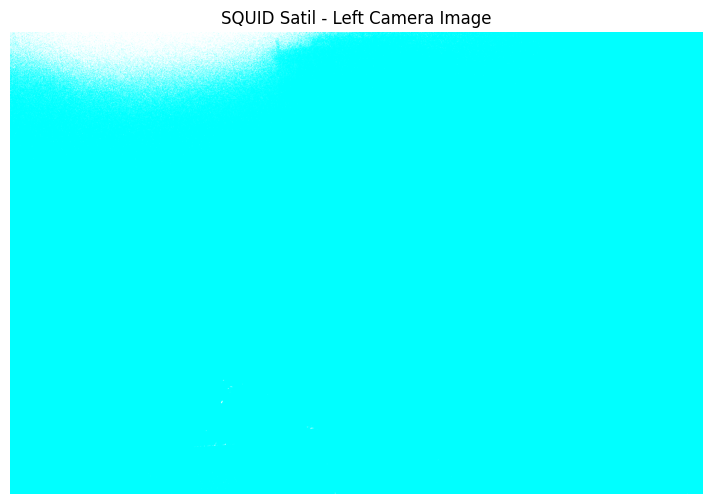

In [16]:
image = cv2.imread(
    "/content/sample_left.tif",
    cv2.IMREAD_UNCHANGED
)

print("Image shape:", image.shape)
print("Image data type:", image.dtype)

plt.figure(figsize=(10, 6))

if image.ndim == 3:
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
else:
    plt.imshow(image, cmap="gray")

plt.title("SQUID Satil - Left Camera Image")
plt.axis("off")
plt.show()

In [17]:
import scipy.io as sio

with zipfile.ZipFile(zip_path, 'r') as z:

    mat_files = [
        f for f in z.namelist()
        if f.endswith("xyzPoints.mat")
    ]

    print("XYZ files found:", len(mat_files))

    for f in mat_files:
        print(f)

XYZ files found: 8
image_set_03/xyzPoints.mat
image_set_06/xyzPoints.mat
image_set_05/xyzPoints.mat
image_set_04/xyzPoints.mat
image_set_01/xyzPoints.mat
image_set_07/xyzPoints.mat
image_set_02/xyzPoints.mat
image_set_08/xyzPoints.mat


In [18]:
mat_path = "/content/xyzPoints_sample.mat"

with zipfile.ZipFile(zip_path, 'r') as z:
    with z.open(mat_files[0]) as source:
        with open(mat_path, 'wb') as target:
            target.write(source.read())

try:
    print(sio.whosmat(mat_path))
except Exception as e:
    print("MATLAB format:", e)

[('imgLeftUndistorted', (1827, 2737, 3), 'double'), ('imgRightUndistorted', (1827, 2737, 3), 'double'), ('xyzPointsLeft', (1827, 2737, 3), 'double'), ('xyzPointsRight', (1827, 2737, 3), 'double')]


In [19]:
with zipfile.ZipFile(zip_path, 'r') as z:

    for f in z.namelist():
        if any(x in f.lower() for x in [
            "calib", "camera", "intrinsic",
            "extrinsic", "readme"
        ]):
            print(f)

image_set_07/distanceFromCamera.mat
image_set_08/distanceFromCamera.mat
image_set_04/distanceFromCamera.mat
image_set_02/distanceFromCamera.mat
image_set_03/distanceFromCamera.mat
image_set_01/distanceFromCamera.mat
image_set_06/distanceFromCamera.mat
image_set_05/distanceFromCamera.mat


In [20]:
import zipfile
import os

with zipfile.ZipFile("/content/Satil.zip", "r") as z:

    set_files = [
        f for f in z.namelist()
        if f.startswith("image_set_01/")
    ]

    for f in set_files:
        if f.endswith((".mat", ".tif")):
            print(f)

image_set_01/LFT_3875.tif
image_set_01/RGT_4336.tif
image_set_01/xyzPoints.mat
image_set_01/distanceFromCamera.mat
image_set_01/RGT_4336resizedUndistort.tif
image_set_01/LFT_3875resizedUndistort.tif


In [21]:
import scipy.io as sio
import zipfile

with zipfile.ZipFile("/content/Satil.zip", "r") as z:

    for filename in [
        "image_set_01/xyzPoints.mat",
        "image_set_01/distanceFromCamera.mat"
    ]:

        print("\nFILE:", filename)

        temp_path = "/content/" + filename.split("/")[-1]

        with z.open(filename) as source:
            with open(temp_path, "wb") as target:
                target.write(source.read())

        try:
            for name, shape, dtype in sio.whosmat(temp_path):
                print(name, "| Shape:", shape, "| Type:", dtype)

        except Exception as e:
            print("Requires MATLAB v7.3 inspection:", e)


FILE: image_set_01/xyzPoints.mat
imgLeftUndistorted | Shape: (1827, 2737, 3) | Type: double
imgRightUndistorted | Shape: (1827, 2737, 3) | Type: double
xyzPointsLeft | Shape: (1827, 2737, 3) | Type: double
xyzPointsRight | Shape: (1827, 2737, 3) | Type: double

FILE: image_set_01/distanceFromCamera.mat
dist_map_l | Shape: (1827, 2737) | Type: double
dist_map_r | Shape: (1827, 2737) | Type: double


In [22]:
import scipy.io as sio
import numpy as np
import matplotlib.pyplot as plt

distance_data = sio.loadmat(
    "/content/distanceFromCamera.mat"
)

print("Available variables:")

for key in distance_data:
    if not key.startswith("__"):
        arr = distance_data[key]

        if isinstance(arr, np.ndarray):
            print(
                key,
                arr.shape,
                arr.dtype
            )

Available variables:
dist_map_l (1827, 2737) float64
dist_map_r (1827, 2737) float64



Variable: dist_map_l
Shape: (1827, 2737)
Minimum: 5.795621106182069
Maximum: 39.99970745638701
Valid pixels: 2787720


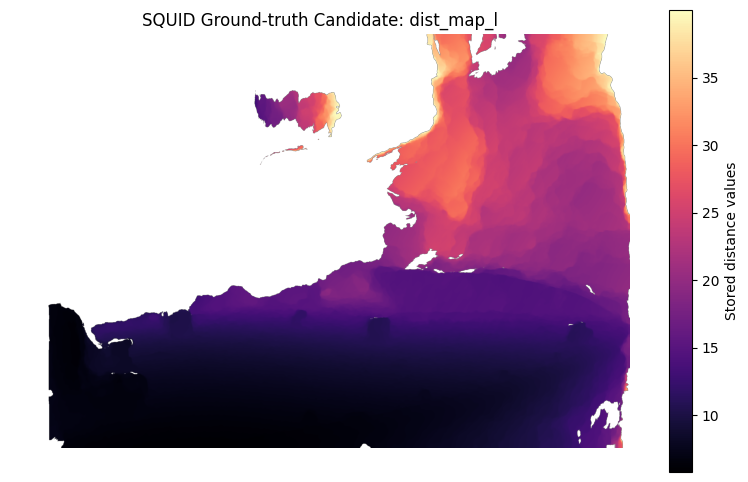


Variable: dist_map_r
Shape: (1827, 2737)
Minimum: 5.872325427510274
Maximum: 39.999953389155316
Valid pixels: 2892899


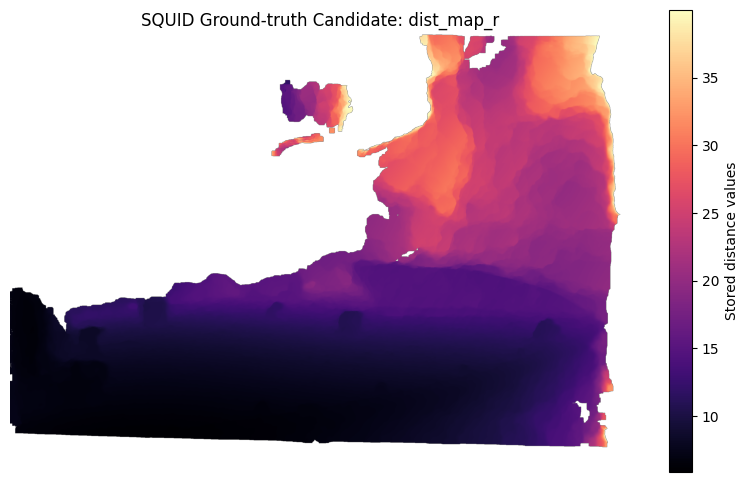

In [23]:
for key, arr in distance_data.items():

    if key.startswith("__"):
        continue

    if isinstance(arr, np.ndarray) and arr.ndim == 2:

        valid = np.isfinite(arr) & (arr > 0)

        print("\nVariable:", key)
        print("Shape:", arr.shape)
        print("Minimum:", np.min(arr[valid]) if valid.any() else "No valid values")
        print("Maximum:", np.max(arr[valid]) if valid.any() else "No valid values")
        print("Valid pixels:", valid.sum())

        if valid.any():
            plt.figure(figsize=(10, 6))

            plt.imshow(
                np.where(valid, arr, np.nan),
                cmap="magma"
            )

            plt.colorbar(label="Stored distance values")
            plt.title("SQUID Ground-truth Candidate: " + key)
            plt.axis("off")
            plt.show()

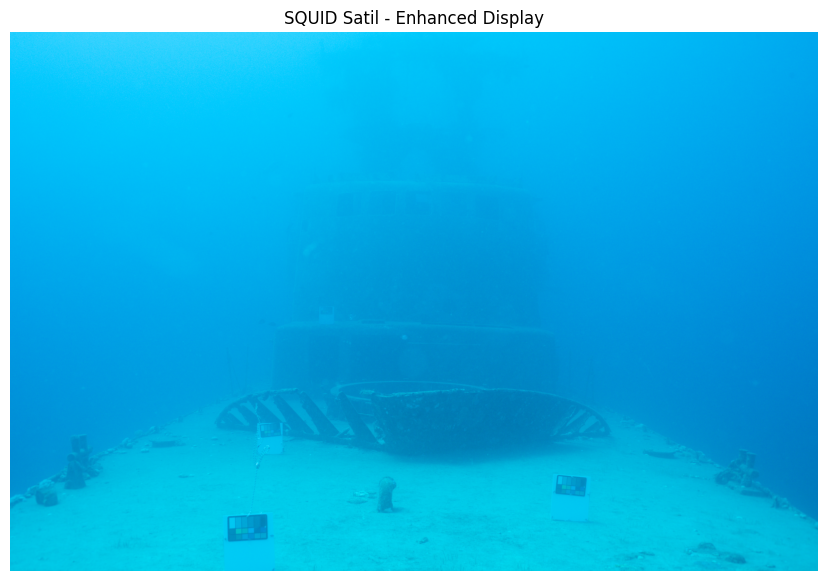

In [24]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread(
    "/content/sample_left.tif",
    cv2.IMREAD_UNCHANGED
)

img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

low, high = np.percentile(img, [1, 99])

display_img = np.clip(
    (img.astype(np.float32) - low) / (high - low + 1e-8),
    0, 1
)

plt.figure(figsize=(12, 7))
plt.imshow(display_img)
plt.title("SQUID Satil - Enhanced Display")
plt.axis("off")
plt.show()

In [25]:
import zipfile
import scipy.io as sio
import numpy as np
from io import BytesIO

zip_path = "/content/Satil.zip"

with zipfile.ZipFile(zip_path, "r") as z:

    # Load left RGB image
    rgb_bytes = z.read("image_set_01/xyzPoints.mat")

    rgb_data = sio.loadmat(
        BytesIO(rgb_bytes),
        variable_names=["imgLeftUndistorted"]
    )

    rgb = rgb_data["imgLeftUndistorted"]

    # Load left ground-truth depth
    depth_bytes = z.read(
        "image_set_01/distanceFromCamera.mat"
    )

    depth_data = sio.loadmat(
        BytesIO(depth_bytes),
        variable_names=["dist_map_l"]
    )

    depth = depth_data["dist_map_l"]

print("RGB shape:", rgb.shape)
print("RGB dtype:", rgb.dtype)

print("Depth shape:", depth.shape)
print("Depth dtype:", depth.dtype)

print("RGB range:", np.nanmin(rgb), np.nanmax(rgb))

valid_mask = np.isfinite(depth) & (depth > 0)

print("Depth minimum:", depth[valid_mask].min())
print("Depth maximum:", depth[valid_mask].max())
print("Valid depth pixels:", valid_mask.sum())

RGB shape: (1827, 2737, 3)
RGB dtype: float64
Depth shape: (1827, 2737)
Depth dtype: float64
RGB range: 0.0 1.0
Depth minimum: 5.795621106182069
Depth maximum: 39.99970745638701
Valid depth pixels: 2787720


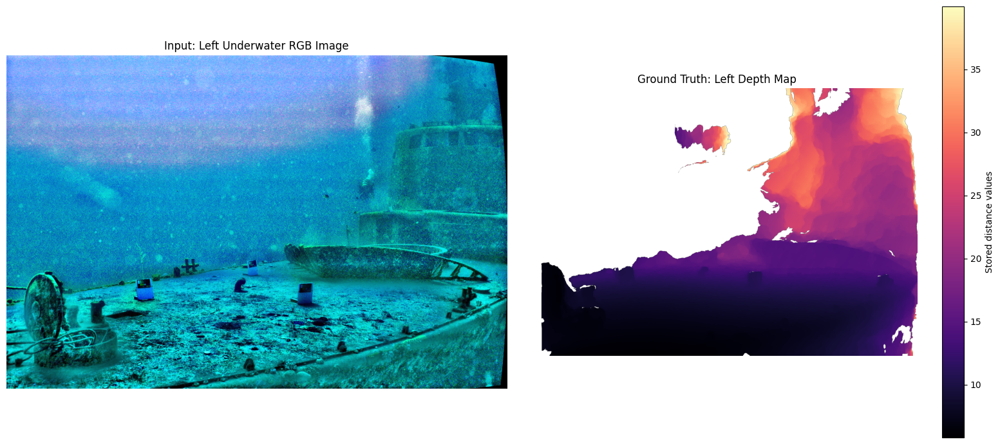

In [26]:
import matplotlib.pyplot as plt

# RGB display normalization
low, high = np.percentile(rgb, [1, 99])

rgb_display = np.clip(
    (rgb.astype(np.float32) - low) / (high - low + 1e-8),
    0, 1
)

# Hide invalid depth pixels
depth_display = np.where(
    valid_mask,
    depth,
    np.nan
)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

axes[0].imshow(rgb_display)
axes[0].set_title("Input: Left Underwater RGB Image")
axes[0].axis("off")

im = axes[1].imshow(depth_display, cmap="magma")
axes[1].set_title("Ground Truth: Left Depth Map")
axes[1].axis("off")

plt.colorbar(im, ax=axes[1], label="Stored distance values")
plt.tight_layout()
plt.show()

In [27]:
assert rgb.shape[:2] == depth.shape, \
    "RGB and depth dimensions do not match!"

assert rgb.ndim == 3 and rgb.shape[2] == 3, \
    "Expected a three-channel RGB image"

print("IMAGE-DEPTH PAIR VERIFIED!")
print("Image dimensions:", rgb.shape[:2])
print("Depth dimensions:", depth.shape)
print("Alignment check: PASSED")

IMAGE-DEPTH PAIR VERIFIED!
Image dimensions: (1827, 2737)
Depth dimensions: (1827, 2737)
Alignment check: PASSED


In [28]:
import zipfile
import scipy.io as sio
import numpy as np
import os
from io import BytesIO

zip_path = "/content/Satil.zip"
BASE = "/content/SQUID_Processed"

for folder in ["images", "depth_maps", "masks"]:
    os.makedirs(f"{BASE}/{folder}", exist_ok=True)

paired_samples = []

with zipfile.ZipFile(zip_path, "r") as z:

    for i in range(1, 9):

        name = f"image_set_{i:02d}"

        rgb_file = f"{name}/xyzPoints.mat"
        depth_file = f"{name}/distanceFromCamera.mat"

        print(f"\nProcessing {name}...")

        try:
            rgb_data = sio.loadmat(
                BytesIO(z.read(rgb_file)),
                variable_names=["imgLeftUndistorted"]
            )

            depth_data = sio.loadmat(
                BytesIO(z.read(depth_file)),
                variable_names=["dist_map_l"]
            )

            rgb = rgb_data["imgLeftUndistorted"]
            depth = depth_data["dist_map_l"].astype(np.float32)

            if rgb.shape[:2] != depth.shape:
                print("Dimension mismatch. Skipping.")
                continue

            mask = np.isfinite(depth) & (depth > 0)

            if not mask.any():
                print("No valid depth values. Skipping.")
                continue

            np.save(f"{BASE}/images/{name}.npy", rgb)
            np.save(f"{BASE}/depth_maps/{name}.npy", depth)
            np.save(f"{BASE}/masks/{name}.npy", mask)

            paired_samples.append(name)

            print("RGB:", rgb.shape)
            print("Depth:", depth.shape)
            print("Valid pixels:", mask.sum())
            print("Saved successfully!")

        except Exception as e:
            print("Error:", name, e)

print("\n==============================")
print("TOTAL SUCCESSFUL PAIRS:", len(paired_samples))
print("DATASET:", paired_samples)


Processing image_set_01...
RGB: (1827, 2737, 3)
Depth: (1827, 2737)
Valid pixels: 2787720
Saved successfully!

Processing image_set_02...
RGB: (1827, 2737, 3)
Depth: (1827, 2737)
Valid pixels: 3848384
Saved successfully!

Processing image_set_03...
RGB: (1827, 2737, 3)
Depth: (1827, 2737)
Valid pixels: 1352769
Saved successfully!

Processing image_set_04...
RGB: (1827, 2737, 3)
Depth: (1827, 2737)
Valid pixels: 606461
Saved successfully!

Processing image_set_05...
RGB: (1827, 2737, 3)
Depth: (1827, 2737)
Valid pixels: 4554354
Saved successfully!

Processing image_set_06...
RGB: (1827, 2737, 3)
Depth: (1827, 2737)
Valid pixels: 2984939
Saved successfully!

Processing image_set_07...
RGB: (1827, 2737, 3)
Depth: (1827, 2737)
Valid pixels: 4491789
Saved successfully!

Processing image_set_08...
RGB: (1827, 2737, 3)
Depth: (1827, 2737)
Valid pixels: 3148627
Saved successfully!

TOTAL SUCCESSFUL PAIRS: 8
DATASET: ['image_set_01', 'image_set_02', 'image_set_03', 'image_set_04', 'image_set_0

In [29]:
import pandas as pd
import numpy as np

records = []

for name in paired_samples:

    rgb = np.load(f"{BASE}/images/{name}.npy", mmap_mode="r")
    depth = np.load(f"{BASE}/depth_maps/{name}.npy", mmap_mode="r")
    mask = np.load(f"{BASE}/masks/{name}.npy", mmap_mode="r")

    records.append({
        "Image Set": name,
        "RGB Shape": str(rgb.shape),
        "Depth Shape": str(depth.shape),
        "Valid Pixels": int(mask.sum()),
        "Minimum Depth": round(float(depth[mask].min()), 3),
        "Maximum Depth": round(float(depth[mask].max()), 3)
    })

dataset_summary = pd.DataFrame(records)

display(dataset_summary)

,Image Set,RGB Shape,Depth Shape,Valid Pixels,Minimum Depth,Maximum Depth
0,image_set_01,"(1827, 2737, 3)","(1827, 2737)",2787720,5.796,40.000
1,image_set_02,"(1827, 2737, 3)","(1827, 2737)",3848384,6.811,53.434
2,image_set_03,"(1827, 2737, 3)","(1827, 2737)",1352769,6.955,39.999
3,image_set_04,"(1827, 2737, 3)","(1827, 2737)",606461,6.738,40.000
4,image_set_05,"(1827, 2737, 3)","(1827, 2737)",4554354,5.754,47.333
5,image_set_06,"(1827, 2737, 3)","(1827, 2737)",2984939,5.622,39.999
6,image_set_07,"(1827, 2737, 3)","(1827, 2737)",4491789,11.509,113.763
7,image_set_08,"(1827, 2737, 3)","(1827, 2737)",3148627,10.092,88.794


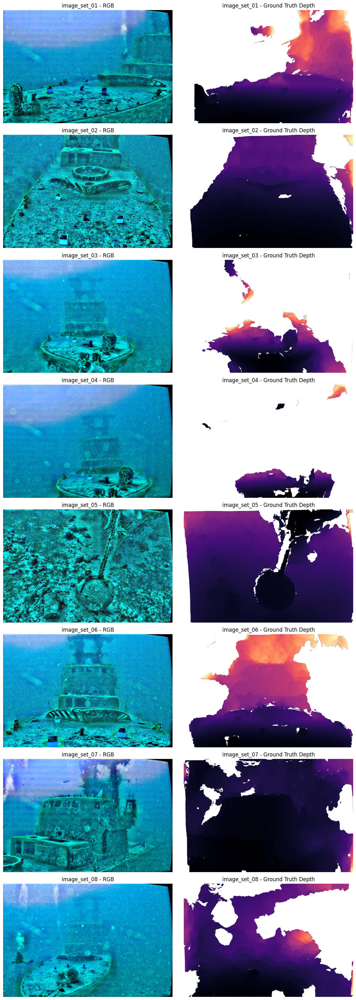

In [30]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(
    len(paired_samples), 2,
    figsize=(12, 4 * len(paired_samples))
)

if len(paired_samples) == 1:
    axes = np.array([axes])

for i, name in enumerate(paired_samples):

    rgb = np.load(f"{BASE}/images/{name}.npy")
    depth = np.load(f"{BASE}/depth_maps/{name}.npy")
    mask = np.load(f"{BASE}/masks/{name}.npy")

    low, high = np.percentile(rgb, [1, 99])

    rgb_display = np.clip(
        (rgb.astype(np.float32) - low) / (high - low + 1e-8),
        0, 1
    )

    axes[i, 0].imshow(rgb_display)
    axes[i, 0].set_title(name + " - RGB")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(
        np.where(mask, depth, np.nan),
        cmap="magma"
    )
    axes[i, 1].set_title(name + " - Ground Truth Depth")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

In [31]:
import cv2
import numpy as np
import os
import pandas as pd

PREP = "/content/SQUID_Preprocessed"

for folder in ["images", "depth_maps", "masks"]:
    os.makedirs(f"{PREP}/{folder}", exist_ok=True)

TARGET_SIZE = (576, 384)  # width, height

preprocess_records = []

for name in paired_samples:

    # Load original arrays
    rgb = np.load(f"{BASE}/images/{name}.npy")
    depth = np.load(f"{BASE}/depth_maps/{name}.npy")
    mask = np.load(f"{BASE}/masks/{name}.npy")

    # Normalize RGB for pretrained neural networks
    if np.issubdtype(rgb.dtype, np.integer):
        rgb_float = rgb.astype(np.float32) / np.iinfo(rgb.dtype).max
    else:
        rgb_float = rgb.astype(np.float32)
        if rgb_float.max() > 1:
            rgb_float /= 255.0

    rgb_float = np.clip(rgb_float, 0, 1)

    # Resize RGB
    rgb_resized = cv2.resize(
        rgb_float,
        TARGET_SIZE,
        interpolation=cv2.INTER_AREA
    )

    # Resize depth without changing its original scale
    depth_resized = cv2.resize(
        depth.astype(np.float32),
        TARGET_SIZE,
        interpolation=cv2.INTER_NEAREST
    )

    # Resize validity mask
    mask_resized = cv2.resize(
        mask.astype(np.uint8),
        TARGET_SIZE,
        interpolation=cv2.INTER_NEAREST
    ).astype(bool)

    # Save processed data
    np.save(f"{PREP}/images/{name}.npy", rgb_resized)
    np.save(f"{PREP}/depth_maps/{name}.npy", depth_resized)
    np.save(f"{PREP}/masks/{name}.npy", mask_resized)

    preprocess_records.append({
        "Image Set": name,
        "RGB Shape": rgb_resized.shape,
        "Depth Shape": depth_resized.shape,
        "Valid Pixels": int(mask_resized.sum()),
        "RGB Min": float(rgb_resized.min()),
        "RGB Max": float(rgb_resized.max())
    })

    print(name, "preprocessed successfully")

preprocess_summary = pd.DataFrame(preprocess_records)

display(preprocess_summary)

image_set_01 preprocessed successfully
image_set_02 preprocessed successfully
image_set_03 preprocessed successfully
image_set_04 preprocessed successfully
image_set_05 preprocessed successfully
image_set_06 preprocessed successfully
image_set_07 preprocessed successfully
image_set_08 preprocessed successfully


,Image Set,RGB Shape,Depth Shape,Valid Pixels,RGB Min,RGB Max
0,image_set_01,"(384, 576, 3)","(384, 576)",123091,0.0,1.000000
1,image_set_02,"(384, 576, 3)","(384, 576)",169871,0.0,0.997615
2,image_set_03,"(384, 576, 3)","(384, 576)",59657,0.0,0.997187
3,image_set_04,"(384, 576, 3)","(384, 576)",26699,0.0,1.000000
4,image_set_05,"(384, 576, 3)","(384, 576)",201125,0.0,0.999055
5,image_set_06,"(384, 576, 3)","(384, 576)",131868,0.0,0.996011
6,image_set_07,"(384, 576, 3)","(384, 576)",198488,0.0,1.000000
7,image_set_08,"(384, 576, 3)","(384, 576)",139218,0.0,0.998871


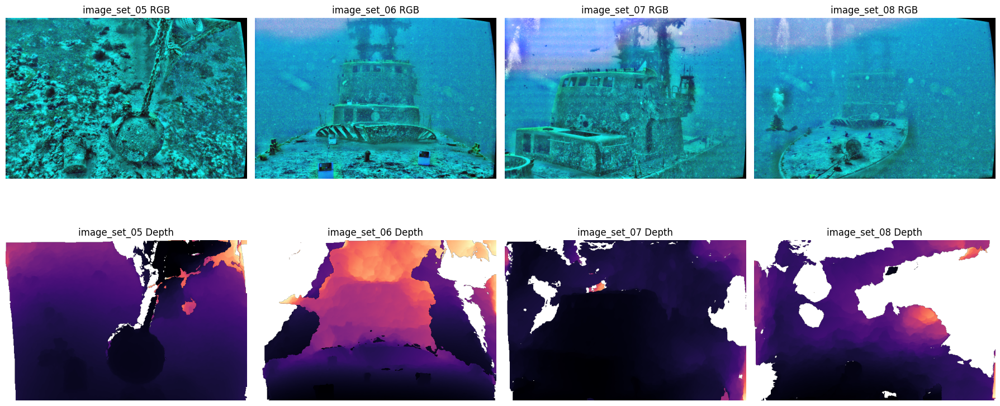

In [32]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 4, figsize=(18, 9))

for i, name in enumerate(paired_samples):

    rgb = np.load(f"{PREP}/images/{name}.npy")
    depth = np.load(f"{PREP}/depth_maps/{name}.npy")
    mask = np.load(f"{PREP}/masks/{name}.npy")

    axes[0, i % 4].imshow(rgb)
    axes[0, i % 4].set_title(name + " RGB")
    axes[0, i % 4].axis("off")

    axes[1, i % 4].imshow(
        np.where(mask, depth, np.nan),
        cmap="magma"
    )
    axes[1, i % 4].set_title(name + " Depth")
    axes[1, i % 4].axis("off")

plt.tight_layout()
plt.show()

In [33]:

import os
import numpy as np

print("VERIFYING PREPROCESSED DATA\n")

for name in paired_samples:

    rgb = np.load(f"{PREP}/images/{name}.npy")
    depth = np.load(f"{PREP}/depth_maps/{name}.npy")
    mask = np.load(f"{PREP}/masks/{name}.npy")

    # Check dimensions
    assert rgb.shape == (384, 576, 3), f"RGB shape error: {name}"
    assert depth.shape == (384, 576), f"Depth shape error: {name}"
    assert mask.shape == (384, 576), f"Mask shape error: {name}"

    # RGB must contain only finite values
    assert np.isfinite(rgb).all(), f"Invalid RGB values: {name}"

    # Valid depth pixels must be finite and positive
    assert np.isfinite(depth[mask]).all(), f"Invalid depth values: {name}"
    assert (depth[mask] > 0).all(), f"Non-positive depth: {name}"

    # Mask must match valid depth pixels
    assert np.array_equal(mask, np.isfinite(depth) & (depth > 0)), \
        f"Mask mismatch: {name}"

    print(f"{name}: VERIFIED | Valid pixels: {mask.sum()}")

print("\nALL PREPROCESSED DATA VERIFIED!")
print("Total image-depth pairs:", len(paired_samples))


VERIFYING PREPROCESSED DATA

image_set_01: VERIFIED | Valid pixels: 123091
image_set_02: VERIFIED | Valid pixels: 169871
image_set_03: VERIFIED | Valid pixels: 59657
image_set_04: VERIFIED | Valid pixels: 26699
image_set_05: VERIFIED | Valid pixels: 201125
image_set_06: VERIFIED | Valid pixels: 131868
image_set_07: VERIFIED | Valid pixels: 198488
image_set_08: VERIFIED | Valid pixels: 139218

ALL PREPROCESSED DATA VERIFIED!
Total image-depth pairs: 8


In [34]:

import os
import numpy as np
import json

# Dataset split
train_samples = paired_samples[:6]
val_samples = paired_samples[6:7]
test_samples = paired_samples[7:]

print("TRAINING SET:", train_samples)
print("VALIDATION SET:", val_samples)
print("TEST SET:", test_samples)

# Verify files exist
for split_name, samples in [
    ("Train", train_samples),
    ("Validation", val_samples),
    ("Test", test_samples)
]:
    for name in samples:
        assert os.path.exists(f"{PREP}/images/{name}.npy")
        assert os.path.exists(f"{PREP}/depth_maps/{name}.npy")
        assert os.path.exists(f"{PREP}/masks/{name}.npy")

    print(f"{split_name}: {len(samples)} samples verified")

# Save split information
split_info = {
    "train": train_samples,
    "validation": val_samples,
    "test": test_samples
}

with open(f"{PREP}/dataset_split.json", "w") as f:
    json.dump(split_info, f, indent=4)

print("\nDATASET SPLIT COMPLETED!")


TRAINING SET: ['image_set_01', 'image_set_02', 'image_set_03', 'image_set_04', 'image_set_05', 'image_set_06']
VALIDATION SET: ['image_set_07']
TEST SET: ['image_set_08']
Train: 6 samples verified
Validation: 1 samples verified
Test: 1 samples verified

DATASET SPLIT COMPLETED!


In [35]:

import torch
import numpy as np
import os

from torch.utils.data import Dataset, DataLoader

# Use GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

class UnderwaterDepthDataset(Dataset):

    def __init__(self, samples, prep_path):
        self.samples = samples
        self.prep_path = prep_path

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):

        name = self.samples[idx]

        # Load RGB image
        rgb = np.load(
            f"{self.prep_path}/images/{name}.npy"
        ).astype(np.float32)

        # Load ground-truth depth
        depth = np.load(
            f"{self.prep_path}/depth_maps/{name}.npy"
        ).astype(np.float32)

        # Load valid-pixel mask
        mask = np.load(
            f"{self.prep_path}/masks/{name}.npy"
        ).astype(bool)

        # Replace invalid depth values
        depth = np.nan_to_num(depth, nan=0.0)

        # Convert RGB from HWC to CHW
        rgb = torch.from_numpy(rgb).permute(2, 0, 1)

        # Convert depth and mask
        depth = torch.from_numpy(depth).unsqueeze(0)
        mask = torch.from_numpy(mask.astype(np.float32)).unsqueeze(0)

        return rgb, depth, mask


# Create datasets
train_dataset = UnderwaterDepthDataset(train_samples, PREP)
val_dataset = UnderwaterDepthDataset(val_samples, PREP)
test_dataset = UnderwaterDepthDataset(test_samples, PREP)

# Create DataLoaders
train_loader = DataLoader(
    train_dataset, batch_size=2, shuffle=True
)

val_loader = DataLoader(
    val_dataset, batch_size=1, shuffle=False
)

test_loader = DataLoader(
    test_dataset, batch_size=1, shuffle=False
)

# Verify one training batch
images, depths, masks = next(iter(train_loader))

print("\nDATA LOADER CREATED SUCCESSFULLY!")
print("RGB batch shape:", images.shape)
print("Depth batch shape:", depths.shape)
print("Mask batch shape:", masks.shape)
print("Valid pixels:", masks.sum().item())


Using device: cuda

DATA LOADER CREATED SUCCESSFULLY!
RGB batch shape: torch.Size([2, 3, 384, 576])
Depth batch shape: torch.Size([2, 1, 384, 576])
Mask batch shape: torch.Size([2, 1, 384, 576])
Valid pixels: 196570.0


In [36]:

import torch
import torch.nn as nn
import torch.nn.functional as F

# CNN Encoder-Decoder Architecture

class UnderwaterDepthCNN(nn.Module):

    def __init__(self):
        super(UnderwaterDepthCNN, self).__init__()

        # ENCODER
        self.encoder = nn.Sequential(

            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True)
        )

        # DECODER
        self.decoder = nn.Sequential(

            nn.Conv2d(256, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),

            nn.Conv2d(128, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),

            nn.Conv2d(64, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),

            nn.Conv2d(32, 1, kernel_size=3, padding=1)
        )

    def forward(self, x):

        input_size = x.shape[-2:]

        features = self.encoder(x)

        depth = self.decoder(features)

        # Restore original image resolution
        depth = F.interpolate(
            depth,
            size=input_size,
            mode="bilinear",
            align_corners=False
        )

        # Positive depth predictions
        depth = F.softplus(depth)

        return depth


# Initialize model
model = UnderwaterDepthCNN().to(device)

print("UNDERWATER DEPTH CNN CREATED!")
print("Device:", device)

# Display architecture
print(model)

# Count trainable parameters
total_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("\nTotal trainable parameters:", total_params)

# Test model with one batch
with torch.no_grad():
    sample_prediction = model(images.to(device))

print("\nInput shape:", images.shape)
print("Predicted depth shape:", sample_prediction.shape)

assert sample_prediction.shape == depths.shape
print("MODEL OUTPUT VERIFIED SUCCESSFULLY!")


UNDERWATER DEPTH CNN CREATED!
Device: cuda
UnderwaterDepthCNN(
  (encoder): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), s

In [37]:

import torch
import torch.nn as nn
import torch.optim as optim

# Masked MAE Loss
def masked_mae_loss(predicted, target, mask):

    valid_pixels = mask > 0

    if valid_pixels.sum() == 0:
        return torch.tensor(0.0, device=predicted.device)

    loss = torch.abs(
        predicted[valid_pixels] - target[valid_pixels]
    ).mean()

    return loss


# Optimizer
criterion = masked_mae_loss

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

# Training configuration
EPOCHS = 20

print("Training configuration ready!")
print("Optimizer: Adam")
print("Learning Rate: 0.001")
print("Loss Function: Masked MAE")
print("Epochs:", EPOCHS)


# Training loop
training_losses = []
validation_losses = []

for epoch in range(EPOCHS):

    # TRAINING
    model.train()
    train_loss = 0.0

    for rgb, depth, mask in train_loader:

        rgb = rgb.to(device)
        depth = depth.to(device)
        mask = mask.to(device)

        optimizer.zero_grad()

        predictions = model(rgb)

        loss = criterion(predictions, depth, mask)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    avg_train_loss = train_loss / len(train_loader)

    # VALIDATION
    model.eval()
    val_loss = 0.0

    with torch.no_grad():

        for rgb, depth, mask in val_loader:

            rgb = rgb.to(device)
            depth = depth.to(device)
            mask = mask.to(device)

            predictions = model(rgb)

            loss = criterion(predictions, depth, mask)

            val_loss += loss.item()

    avg_val_loss = val_loss / len(val_loader)

    training_losses.append(avg_train_loss)
    validation_losses.append(avg_val_loss)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Training Loss: {avg_train_loss:.4f} | "
        f"Validation Loss: {avg_val_loss:.4f}"
    )

print("\nTRAINING COMPLETED!")


Training configuration ready!
Optimizer: Adam
Learning Rate: 0.001
Loss Function: Masked MAE
Epochs: 20
Epoch [1/20] Training Loss: 13.9778 | Validation Loss: 19.8784
Epoch [2/20] Training Loss: 12.5413 | Validation Loss: 20.0921
Epoch [3/20] Training Loss: 12.0183 | Validation Loss: 20.1646
Epoch [4/20] Training Loss: 11.2110 | Validation Loss: 20.0950
Epoch [5/20] Training Loss: 11.0488 | Validation Loss: 20.0157
Epoch [6/20] Training Loss: 11.2079 | Validation Loss: 19.9070
Epoch [7/20] Training Loss: 9.9957 | Validation Loss: 19.8131
Epoch [8/20] Training Loss: 10.0688 | Validation Loss: 19.7127
Epoch [9/20] Training Loss: 8.9862 | Validation Loss: 19.6103
Epoch [10/20] Training Loss: 8.8793 | Validation Loss: 19.4043
Epoch [11/20] Training Loss: 7.9788 | Validation Loss: 18.9111
Epoch [12/20] Training Loss: 7.8360 | Validation Loss: 18.2857
Epoch [13/20] Training Loss: 7.1102 | Validation Loss: 17.6540
Epoch [14/20] Training Loss: 7.0869 | Validation Loss: 17.2738
Epoch [15/20] Tr

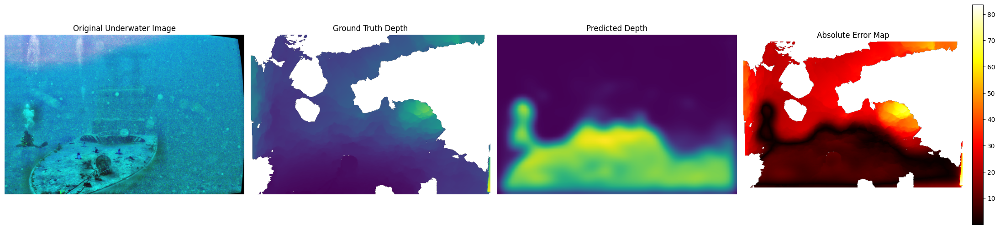

Prediction shape: (384, 576)
Ground truth shape: (384, 576)
Mean Absolute Error: 17.150827


In [38]:

import torch
import numpy as np
import matplotlib.pyplot as plt

# Load the trained model
model.eval()

# Select one test image
rgb, depth, mask = test_dataset[0]

# Add batch dimension and move to GPU
input_image = rgb.unsqueeze(0).to(device)

# Generate prediction
with torch.no_grad():
    predicted_depth = model(input_image)

# Convert tensors to NumPy
original_image = rgb.permute(1, 2, 0).numpy()
ground_truth = depth.squeeze().numpy()
prediction = predicted_depth.squeeze().cpu().numpy()
valid_mask = mask.squeeze().numpy() > 0

# Calculate absolute error only on valid pixels
absolute_error = np.full_like(ground_truth, np.nan)

absolute_error[valid_mask] = np.abs(
    ground_truth[valid_mask] -
    prediction[valid_mask]
)

# Visualization
fig, axes = plt.subplots(1, 4, figsize=(22, 6))

axes[0].imshow(np.clip(original_image, 0, 1))
axes[0].set_title("Original Underwater Image")

axes[1].imshow(
    np.ma.masked_where(~valid_mask, ground_truth),
    cmap="viridis"
)
axes[1].set_title("Ground Truth Depth")

axes[2].imshow(prediction, cmap="viridis")
axes[2].set_title("Predicted Depth")

im = axes[3].imshow(absolute_error, cmap="hot")
axes[3].set_title("Absolute Error Map")

for ax in axes:
    ax.axis("off")

fig.colorbar(im, ax=axes[3], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

print("Prediction shape:", prediction.shape)
print("Ground truth shape:", ground_truth.shape)
print("Mean Absolute Error:",
      np.nanmean(absolute_error))


In [39]:

# Calculate metrics on valid test pixels

valid_gt = ground_truth[valid_mask]
valid_pred = prediction[valid_mask]

# MAE
mae = np.mean(np.abs(valid_gt - valid_pred))

# MSE
mse = np.mean((valid_gt - valid_pred) ** 2)

# RMSE
rmse = np.sqrt(mse)

# Absolute Relative Error
abs_rel = np.mean(
    np.abs(valid_gt - valid_pred) /
    np.maximum(valid_gt, 1e-6)
)

# Delta accuracy
ratio = np.maximum(
    valid_gt / np.maximum(valid_pred, 1e-6),
    valid_pred / np.maximum(valid_gt, 1e-6)
)

delta_1 = np.mean(ratio < 1.25)

print("UNDERWATER DEPTH ESTIMATION RESULTS")
print("-----------------------------------")
print(f"MAE       : {mae:.4f}")
print(f"MSE       : {mse:.4f}")
print(f"RMSE      : {rmse:.4f}")
print(f"Abs Rel   : {abs_rel:.4f}")
print(f"Delta < 1.25 : {delta_1:.4f}")


UNDERWATER DEPTH ESTIMATION RESULTS
-----------------------------------
MAE       : 17.1508
MSE       : 488.5966
RMSE      : 22.1042
Abs Rel   : 0.6188
Delta < 1.25 : 0.1877


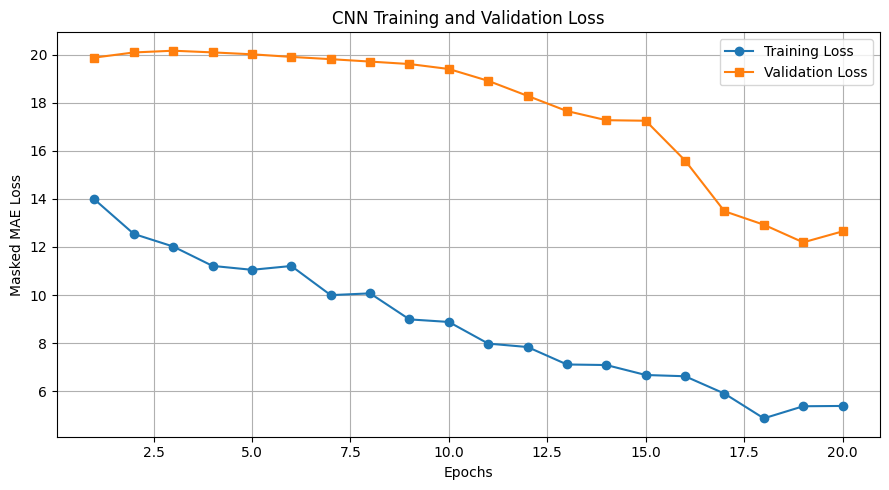

In [40]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(training_losses) + 1),
    training_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    range(1, len(validation_losses) + 1),
    validation_losses,
    marker="s",
    label="Validation Loss"
)

plt.xlabel("Epochs")
plt.ylabel("Masked MAE Loss")
plt.title("CNN Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [41]:

import os
import torch

MODEL_PATH = "/content/underwater_depth_cnn.pth"

torch.save({
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "training_losses": training_losses,
    "validation_losses": validation_losses
}, MODEL_PATH)

print("MODEL SAVED SUCCESSFULLY!")
print("Location:", MODEL_PATH)

print("File size:",
      round(os.path.getsize(MODEL_PATH) / (1024 * 1024), 2),
      "MB")


MODEL SAVED SUCCESSFULLY!
Location: /content/underwater_depth_cnn.pth
File size: 8.94 MB


In [42]:

from google.colab import files

files.download("/content/underwater_depth_cnn.pth")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [43]:
import os

# List folders in Google Drive
base_path = "/content/drive/MyDrive"

for root, dirs, files in os.walk(base_path):

    level = root.replace(base_path, "").count(os.sep)

    if level > 3:
        dirs[:] = []
        continue

    print("Folder:", root)
    print("Files:", files[:5])
    print("-" * 50)

In [44]:
import os

# Apne SQUID dataset ka folder path
dataset_path = "/content/drive/MyDrive/SQUID"

for root, dirs, files in os.walk(dataset_path):
    print("\nFolder:", root)
    print("Number of files:", len(files))
    print("Sample files:", files[:10])

In [45]:
from glob import glob

image_extensions = ["*.png", "*.jpg", "*.jpeg", "*.bmp", "*.tif"]

images = []

for ext in image_extensions:
    images.extend(
        glob(dataset_path + "/**/" + ext, recursive=True)
    )

print("Total images found:", len(images))

for img in images[:10]:
    print(img)

Total images found: 0


In [46]:
%whos

Variable                 Type                      Data/Info
------------------------------------------------------------
BASE                     str                       /content/SQUID_Processed
BytesIO                  type                      <class '_io.BytesIO'>
Counter                  type                      <class 'collections.Counter'>
DataLoader               type                      <class 'torch.utils.data.dataloader.DataLoader'>
Dataset                  type                      <class 'torch.utils.data.dataset.Dataset'>
EPOCHS                   int                       20
F                        module                    <module 'torch.nn.functio<...>/torch/nn/functional.py'>
MODEL_PATH               str                       /content/underwater_depth_cnn.pth
PREP                     str                       /content/SQUID_Preprocessed
TARGET_SIZE              tuple                     n=2
UnderwaterDepthCNN       type                      <class '__main__.Underw

In [47]:
import os

BASE = "/content/SQUID_Processed"

print("Folders inside dataset:")
for item in os.listdir(BASE):
    path = os.path.join(BASE, item)
    print(item, "->", "Folder" if os.path.isdir(path) else "File")

Folders inside dataset:
masks -> Folder
images -> Folder
depth_maps -> Folder


In [48]:
import os

for root, dirs, files in os.walk(BASE):
    print("\nFolder:", root)
    print("Files:", files[:10])


Folder: /content/SQUID_Processed
Files: []

Folder: /content/SQUID_Processed/masks
Files: ['image_set_05.npy', 'image_set_02.npy', 'image_set_04.npy', 'image_set_06.npy', 'image_set_01.npy', 'image_set_07.npy', 'image_set_08.npy', 'image_set_03.npy']

Folder: /content/SQUID_Processed/images
Files: ['image_set_05.npy', 'image_set_02.npy', 'image_set_04.npy', 'image_set_06.npy', 'image_set_01.npy', 'image_set_07.npy', 'image_set_08.npy', 'image_set_03.npy']

Folder: /content/SQUID_Processed/depth_maps
Files: ['image_set_05.npy', 'image_set_02.npy', 'image_set_04.npy', 'image_set_06.npy', 'image_set_01.npy', 'image_set_07.npy', 'image_set_08.npy', 'image_set_03.npy']


In [49]:
print("Dataset class:")
print(UnderwaterDepthDataset)

print("\nDataset length:")
print(len(train_loader.dataset))

print("\nOne sample:")
sample = train_loader.dataset[0]

print(type(sample))
print(sample)

Dataset class:
<class '__main__.UnderwaterDepthDataset'>

Dataset length:
6

One sample:
<class 'tuple'>
(tensor([[[0.4799, 0.5423, 0.6441,  ..., 0.0000, 0.0000, 0.0000],
         [0.5811, 0.5322, 0.5903,  ..., 0.0000, 0.0000, 0.0000],
         [0.4542, 0.5974, 0.5177,  ..., 0.0000, 0.0000, 0.0000],
         ...,
         [0.0886, 0.0886, 0.0886,  ..., 0.0000, 0.0000, 0.0000],
         [0.0886, 0.0886, 0.0886,  ..., 0.0000, 0.0000, 0.0000],
         [0.0886, 0.0886, 0.0886,  ..., 0.0000, 0.0000, 0.0000]],

        [[0.7476, 0.7235, 0.7375,  ..., 0.0000, 0.0000, 0.0000],
         [0.7025, 0.6823, 0.7381,  ..., 0.0000, 0.0000, 0.0000],
         [0.6605, 0.6325, 0.6760,  ..., 0.0000, 0.0000, 0.0000],
         ...,
         [0.3810, 0.5032, 0.4425,  ..., 0.0000, 0.0000, 0.0000],
         [0.2484, 0.5592, 0.5884,  ..., 0.0000, 0.0000, 0.0000],
         [0.2876, 0.7113, 0.6790,  ..., 0.0000, 0.0000, 0.0000]],

        [[1.0000, 1.0000, 1.0000,  ..., 0.0000, 0.0000, 0.0000],
         [1.0000,

In [50]:
sample = train_loader.dataset[0]

if isinstance(sample, (tuple, list)):
    for i, item in enumerate(sample):
        if hasattr(item, "shape"):
            print(f"Item {i} shape:", item.shape)
        else:
            print(f"Item {i} type:", type(item))

Item 0 shape: torch.Size([3, 384, 576])
Item 1 shape: torch.Size([1, 384, 576])
Item 2 shape: torch.Size([1, 384, 576])


In [51]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cuda


In [52]:
class MobileNetV2Depth(nn.Module):

    def __init__(self):
        super(MobileNetV2Depth, self).__init__()

        # Pretrained MobileNetV2 encoder
        mobilenet = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)

        self.encoder = mobilenet.features

        # Depth decoder
        self.decoder = nn.Sequential(

            nn.Conv2d(1280, 512, 3, padding=1),
            nn.BatchNorm2d(512),
            nn.ReLU(inplace=True),

            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False),

            nn.Conv2d(512, 256, 3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),

            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False),

            nn.Conv2d(256, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),

            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False),

            nn.Conv2d(128, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),

            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False),

            nn.Conv2d(64, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),

            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False),

            nn.Conv2d(32, 1, kernel_size=3, padding=1)
        )

    def forward(self, x):

        features = self.encoder(x)
        depth = self.decoder(features)

        depth = torch.sigmoid(depth)

        return depth

In [53]:
mobilenet_model = MobileNetV2Depth().to(device)

print(mobilenet_model)

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 146MB/s]


MobileNetV2Depth(
  (encoder): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1, 1), bias=False

In [54]:
dummy_input = torch.randn(1, 3, 256, 256).to(device)

with torch.no_grad():
    output = mobilenet_model(dummy_input)

print("Input shape:", dummy_input.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([1, 3, 256, 256])
Output shape: torch.Size([1, 1, 256, 256])


In [55]:
import torch
import torch.nn as nn

criterion = nn.MSELoss()

optimizer = torch.optim.AdamW(
    mobilenet_model.parameters(),
    lr=0.0001,
    weight_decay=1e-5
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.5,
    patience=3
)

print("Loss function:", criterion)
print("Optimizer: AdamW")
print("Learning rate: 0.0001")

Loss function: MSELoss()
Optimizer: AdamW
Learning rate: 0.0001


In [56]:
def train_one_epoch(model, loader, optimizer, criterion, device):

    model.train()
    total_loss = 0

    for images, depths in loader:

        images = images.to(device)
        depths = depths.to(device)

        if depths.ndim == 3:
            depths = depths.unsqueeze(1)

        optimizer.zero_grad()

        predictions = model(images)

        loss = criterion(predictions, depths)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(loader)

In [57]:
def validate_one_epoch(model, loader, criterion, device):

    model.eval()
    total_loss = 0

    with torch.no_grad():

        for images, depths in loader:

            images = images.to(device)
            depths = depths.to(device)

            if depths.ndim == 3:
                depths = depths.unsqueeze(1)

            predictions = model(images)

            loss = criterion(predictions, depths)

            total_loss += loss.item()

    return total_loss / len(loader)

In [59]:
batch = next(iter(train_loader))

print("Batch type:", type(batch))
print("Batch length:", len(batch))

for i, item in enumerate(batch):
    print(f"Item {i}:")
    print("Type:", type(item))

    if hasattr(item, "shape"):
        print("Shape:", item.shape)

    elif isinstance(item, dict):
        print("Keys:", item.keys())

Batch type: <class 'list'>
Batch length: 3
Item 0:
Type: <class 'torch.Tensor'>
Shape: torch.Size([2, 3, 384, 576])
Item 1:
Type: <class 'torch.Tensor'>
Shape: torch.Size([2, 1, 384, 576])
Item 2:
Type: <class 'torch.Tensor'>
Shape: torch.Size([2, 1, 384, 576])


In [60]:
def train_one_epoch(model, loader, optimizer, criterion, device):

    model.train()
    total_loss = 0

    for images, depths, masks in loader:

        images = images.to(device)
        depths = depths.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        predictions = model(images)

        # Resize prediction if output and target dimensions differ
        if predictions.shape != depths.shape:
            predictions = F.interpolate(
                predictions,
                size=depths.shape[-2:],
                mode="bilinear",
                align_corners=False
            )

        # Calculate loss only on valid pixels
        valid_pixels = masks > 0

        if valid_pixels.sum() == 0:
            continue

        loss = ((predictions - depths) ** 2)[valid_pixels].mean()

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(loader)

In [61]:
def validate_one_epoch(model, loader, criterion, device):

    model.eval()
    total_loss = 0
    batches = 0

    with torch.no_grad():

        for images, depths, masks in loader:

            images = images.to(device)
            depths = depths.to(device)
            masks = masks.to(device)

            predictions = model(images)

            if predictions.shape != depths.shape:
                predictions = F.interpolate(
                    predictions,
                    size=depths.shape[-2:],
                    mode="bilinear",
                    align_corners=False
                )

            valid_pixels = masks > 0

            if valid_pixels.sum() == 0:
                continue

            loss = ((predictions - depths) ** 2)[valid_pixels].mean()

            total_loss += loss.item()
            batches += 1

    return total_loss / max(batches, 1)

In [62]:
print("Third tensor min:", batch[2].min().item())
print("Third tensor max:", batch[2].max().item())
print("Third tensor unique sample:", torch.unique(batch[2])[:20])

Third tensor min: 0.0
Third tensor max: 1.0
Third tensor unique sample: tensor([0., 1.])


Device: cuda
Image shape: torch.Size([2, 3, 384, 576])
Depth shape: torch.Size([2, 1, 384, 576])
Mask shape: torch.Size([2, 1, 384, 576])
Depth range: 0.0 to 53.26231002807617

MobileNetV2 initialized successfully!
Total parameters: 5566305

========== TRAINING STARTED ==========

Epoch [1/20] | Train Loss: 242.431575 | Val Loss: 455.908783
Best model checkpoint saved!
Epoch [2/20] | Train Loss: 232.852580 | Val Loss: 456.225555
Epoch [3/20] | Train Loss: 242.055003 | Val Loss: 456.471191
Epoch [4/20] | Train Loss: 233.576477 | Val Loss: 456.872925
Epoch [5/20] | Train Loss: 245.970378 | Val Loss: 457.347717
Epoch [6/20] | Train Loss: 222.299835 | Val Loss: 457.523376
Epoch [7/20] | Train Loss: 230.408010 | Val Loss: 457.366943
Epoch [8/20] | Train Loss: 220.554454 | Val Loss: 456.280212
Epoch [9/20] | Train Loss: 236.560506 | Val Loss: 455.796509
Best model checkpoint saved!
Epoch [10/20] | Train Loss: 219.391134 | Val Loss: 455.000061
Best model checkpoint saved!
Epoch [11/20] | Trai

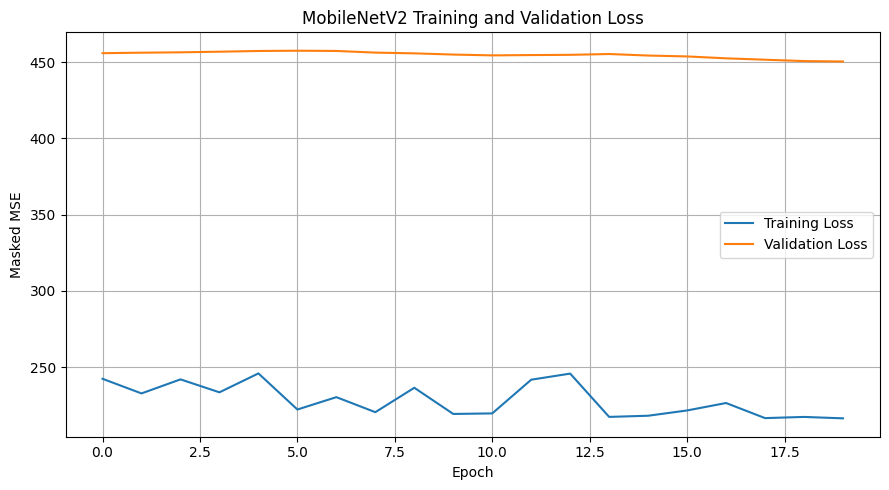


========== EVALUATING TEST SET ==========

MSE: 687.068971
RMSE: 26.212001
MAE: 24.247026
Abs Rel: 0.966393
Delta 1: 0.000000
Delta 2: 0.000000
Delta 3: 0.000000


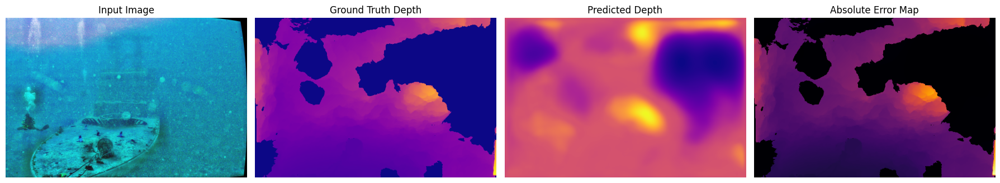


========== FINAL RESULTS ==========
Architecture        MSE      RMSE       MAE  Abs Rel  Delta 1  Delta 2  Delta 3
 MobileNetV2 687.068971 26.212001 24.247026 0.966393      0.0      0.0      0.0

Metrics saved: /content/mobilenetv2_metrics.csv
Model saved: /content/mobilenetv2_best.pth
Training graph saved: /content/mobilenetv2_loss.png
Prediction saved: /content/mobilenetv2_prediction.png

ALL STEPS COMPLETED SUCCESSFULLY!


In [64]:
# ============================================================
# ROBUST UNDERWATER MONOCULAR DEPTH ESTIMATION
# MobileNetV2 | Complete Training & Evaluation Pipeline
# ============================================================

import os
import copy
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from torchvision import models

# ============================================================
# 1. SETUP
# ============================================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

EPOCHS = 20
LR = 1e-4

MODEL_PATH = "/content/mobilenetv2_best.pth"
METRICS_PATH = "/content/mobilenetv2_metrics.csv"

print("Device:", device)

assert "train_loader" in globals(), "train_loader not found"
assert "val_loader" in globals(), "val_loader not found"

if "test_loader" in globals():
    evaluation_loader = test_loader
    evaluation_name = "Test Set"
else:
    evaluation_loader = val_loader
    evaluation_name = "Validation Set (test_loader unavailable)"

batch = next(iter(train_loader))

print("Image shape:", batch[0].shape)
print("Depth shape:", batch[1].shape)
print("Mask shape:", batch[2].shape)
print("Depth range:", batch[1].min().item(), "to", batch[1].max().item())


# ============================================================
# 2. MOBILENETV2 ARCHITECTURE
# ============================================================

class MobileNetV2Depth(nn.Module):

    def __init__(self):
        super().__init__()

        backbone = models.mobilenet_v2(
            weights=models.MobileNet_V2_Weights.DEFAULT
        )

        self.encoder = backbone.features

        self.decoder = nn.Sequential(

            nn.Conv2d(1280, 256, 3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),

            nn.Upsample(scale_factor=2, mode="bilinear",
                        align_corners=False),

            nn.Conv2d(256, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),

            nn.Upsample(scale_factor=2, mode="bilinear",
                        align_corners=False),

            nn.Conv2d(128, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),

            nn.Upsample(scale_factor=2, mode="bilinear",
                        align_corners=False),

            nn.Conv2d(64, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),

            nn.Upsample(scale_factor=2, mode="bilinear",
                        align_corners=False),

            nn.Conv2d(32, 16, 3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True)
        )

        self.final_layer = nn.Conv2d(
            16, 1, kernel_size=3, padding=1
        )

        # Positive depth output with no upper limit
        self.output_activation = nn.Softplus()

    def forward(self, x):

        original_size = x.shape[-2:]

        features = self.encoder(x)
        decoded = self.decoder(features)

        decoded = F.interpolate(
            decoded,
            size=original_size,
            mode="bilinear",
            align_corners=False
        )

        depth = self.final_layer(decoded)

        # IMPORTANT: depth is NOT restricted to 0-1
        depth = self.output_activation(depth)

        return depth


# ============================================================
# 3. INITIALIZE MODEL
# ============================================================

model = MobileNetV2Depth().to(device)

print("\nMobileNetV2 initialized successfully!")

print(
    "Total parameters:",
    sum(p.numel() for p in model.parameters())
)


# ============================================================
# 4. MASKED MSE LOSS
# ============================================================

def masked_mse(prediction, target, mask):

    valid = mask > 0

    if valid.sum() == 0:
        return None

    return ((prediction - target) ** 2)[valid].mean()


# ============================================================
# 5. TRAIN FUNCTION
# ============================================================

def train_one_epoch(model, loader, optimizer, device):

    model.train()

    total_loss = 0
    batches = 0

    for images, depths, masks in loader:

        images = images.to(device, dtype=torch.float32)
        depths = depths.to(device, dtype=torch.float32)
        masks = masks.to(device, dtype=torch.float32)

        optimizer.zero_grad(set_to_none=True)

        predictions = model(images)

        loss = masked_mse(predictions, depths, masks)

        if loss is None:
            continue

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=1.0
        )

        optimizer.step()

        total_loss += loss.item()
        batches += 1

    return total_loss / max(batches, 1)


# ============================================================
# 6. VALIDATION FUNCTION
# ============================================================

def validate_one_epoch(model, loader, device):

    model.eval()

    total_loss = 0
    batches = 0

    with torch.no_grad():

        for images, depths, masks in loader:

            images = images.to(device, dtype=torch.float32)
            depths = depths.to(device, dtype=torch.float32)
            masks = masks.to(device, dtype=torch.float32)

            predictions = model(images)

            loss = masked_mse(predictions, depths, masks)

            if loss is None:
                continue

            total_loss += loss.item()
            batches += 1

    return total_loss / max(batches, 1)


# ============================================================
# 7. OPTIMIZER
# ============================================================

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LR,
    weight_decay=1e-5
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)


# ============================================================
# 8. TRAINING LOOP
# ============================================================

train_losses = []
val_losses = []

best_val_loss = float("inf")
best_weights = None

print("\n========== TRAINING STARTED ==========\n")

for epoch in range(EPOCHS):

    train_loss = train_one_epoch(
        model, train_loader, optimizer, device
    )

    val_loss = validate_one_epoch(
        model, val_loader, device
    )

    scheduler.step(val_loss)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.6f} | "
        f"Val Loss: {val_loss:.6f}"
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_weights = copy.deepcopy(model.state_dict())

        torch.save(best_weights, MODEL_PATH)

        print("Best model checkpoint saved!")

print("\n========== TRAINING COMPLETE ==========")

if best_weights is not None:
    model.load_state_dict(best_weights)

print("Best Validation Loss:", best_val_loss)
print("Model saved at:", MODEL_PATH)


# ============================================================
# 9. TRAINING GRAPH
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Masked MSE")
plt.title("MobileNetV2 Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("/content/mobilenetv2_loss.png", dpi=300)
plt.show()


# ============================================================
# 10. TEST EVALUATION
# ============================================================

def evaluate_model(model, loader, device):

    model.eval()

    total_squared_error = 0.0
    total_absolute_error = 0.0
    total_abs_rel = 0.0

    total_delta1 = 0
    total_delta2 = 0
    total_delta3 = 0

    total_valid_pixels = 0

    with torch.no_grad():

        for images, depths, masks in loader:

            images = images.to(device, dtype=torch.float32)
            depths = depths.to(device, dtype=torch.float32)
            masks = masks.to(device, dtype=torch.float32)

            predictions = model(images)

            valid = masks > 0

            pred = predictions[valid]
            target = depths[valid]

            if pred.numel() == 0:
                continue

            error = pred - target

            total_squared_error += (error ** 2).sum().item()
            total_absolute_error += error.abs().sum().item()

            # Avoid division by zero for Abs Rel
            safe_target = torch.clamp(target, min=1e-6)

            total_abs_rel += (
                torch.abs(error) / safe_target
            ).sum().item()

            ratio = torch.maximum(
                pred / torch.clamp(target, min=1e-6),
                target / torch.clamp(pred, min=1e-6)
            )

            total_delta1 += (ratio < 1.25).sum().item()
            total_delta2 += (ratio < 1.25**2).sum().item()
            total_delta3 += (ratio < 1.25**3).sum().item()

            total_valid_pixels += pred.numel()

    N = max(total_valid_pixels, 1)

    mse = total_squared_error / N
    rmse = np.sqrt(mse)
    mae = total_absolute_error / N
    abs_rel = total_abs_rel / N

    return {
        "MSE": mse,
        "RMSE": rmse,
        "MAE": mae,
        "Abs Rel": abs_rel,
        "Delta 1": total_delta1 / N,
        "Delta 2": total_delta2 / N,
        "Delta 3": total_delta3 / N
    }


print(f"\n========== EVALUATING {evaluation_name.upper()} ==========\n")

metrics = evaluate_model(
    model, evaluation_loader, device
)

for key, value in metrics.items():
    print(f"{key}: {value:.6f}")


# ============================================================
# 11. PREDICTION VISUALIZATION
# ============================================================

model.eval()

images, depths, masks = next(iter(evaluation_loader))

with torch.no_grad():

    image = images[0:1].to(device)

    prediction = model(image)

    prediction = F.interpolate(
        prediction,
        size=depths[0].shape[-2:],
        mode="bilinear",
        align_corners=False
    )

image = images[0].cpu()
ground_truth = depths[0].cpu().squeeze()
predicted_depth = prediction[0].cpu().squeeze()
mask = masks[0].cpu().squeeze()

image_display = image.permute(1, 2, 0).numpy()
image_display = np.clip(image_display, 0, 1)

error_map = torch.abs(ground_truth - predicted_depth)

plt.figure(figsize=(18, 5))

plt.subplot(1, 4, 1)
plt.imshow(image_display)
plt.title("Input Image")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(ground_truth, cmap="plasma")
plt.title("Ground Truth Depth")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(predicted_depth, cmap="plasma")
plt.title("Predicted Depth")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(error_map, cmap="inferno")
plt.title("Absolute Error Map")
plt.axis("off")

plt.tight_layout()
plt.savefig("/content/mobilenetv2_prediction.png", dpi=300)
plt.show()


# ============================================================
# 12. SAVE METRICS CSV
# ============================================================

metrics_df = pd.DataFrame([{
    "Architecture": "MobileNetV2",
    **metrics
}])

metrics_df.to_csv(METRICS_PATH, index=False)

print("\n========== FINAL RESULTS ==========")
print(metrics_df.to_string(index=False))

print("\nMetrics saved:", METRICS_PATH)
print("Model saved:", MODEL_PATH)
print("Training graph saved: /content/mobilenetv2_loss.png")
print("Prediction saved: /content/mobilenetv2_prediction.png")

print("\nALL STEPS COMPLETED SUCCESSFULLY!")

In [65]:
model.eval()

with torch.no_grad():

    images, depths, masks = next(iter(evaluation_loader))

    images = images.to(device)

    predictions = model(images)

    valid = masks > 0

    pred_valid = predictions.cpu()[valid]
    gt_valid = depths.cpu()[valid]

    print("========== PREDICTION DIAGNOSTICS ==========")

    print("\nPREDICTED DEPTH")
    print("Min:", pred_valid.min().item())
    print("Max:", pred_valid.max().item())
    print("Mean:", pred_valid.mean().item())
    print("Median:", pred_valid.median().item())

    print("\nGROUND TRUTH DEPTH")
    print("Min:", gt_valid.min().item())
    print("Max:", gt_valid.max().item())
    print("Mean:", gt_valid.mean().item())
    print("Median:", gt_valid.median().item())

    print("\nINPUT IMAGE")
    print("Min:", images.min().item())
    print("Max:", images.max().item())
    print("Mean:", images.mean().item())

    ratio = torch.maximum(
        pred_valid / gt_valid.clamp(min=1e-6),
        gt_valid / pred_valid.clamp(min=1e-6)
    )

    print("\nDELTA METRICS")
    print("Delta 1:", (ratio < 1.25).float().mean().item())
    print("Delta 2:", (ratio < 1.25**2).float().mean().item())
    print("Delta 3:", (ratio < 1.25**3).float().mean().item())

========== PREDICTION DIAGNOSTICS ==========

PREDICTED DEPTH
Min: 0.1709703505039215
Max: 1.3125841617584229
Mean: 0.7247886061668396
Median: 0.7392879724502563

GROUND TRUTH DEPTH
Min: 10.09450626373291
Max: 88.39826202392578
Mean: 24.971811294555664
Median: 23.640464782714844

INPUT IMAGE
Min: 0.0
Max: 0.9988711476325989
Mean: 0.46512627601623535

DELTA METRICS
Delta 1: 0.0
Delta 2: 0.0
Delta 3: 0.0


Device: cuda
Train batches: 3
Validation batches: 1
Evaluation: test_loader

MobileNetV2 Depth Model created successfully!
Trainable parameters: 5566905

========== TRAINING STARTED ==========

Epoch [01/30] | Train Loss: 0.139142 | Val Loss: 0.101803 | Decoder LR: 0.0001000
  --> Best model saved
Epoch [02/30] | Train Loss: 0.095007 | Val Loss: 0.098391 | Decoder LR: 0.0001000
  --> Best model saved
Epoch [03/30] | Train Loss: 0.083066 | Val Loss: 0.094911 | Decoder LR: 0.0001000
  --> Best model saved
Epoch [04/30] | Train Loss: 0.073203 | Val Loss: 0.091101 | Decoder LR: 0.0001000
  --> Best model saved
Epoch [05/30] | Train Loss: 0.063710 | Val Loss: 0.087273 | Decoder LR: 0.0001000
  --> Best model saved
Epoch [06/30] | Train Loss: 0.058316 | Val Loss: 0.082675 | Decoder LR: 0.0001000
  --> Best model saved
Epoch [07/30] | Train Loss: 0.058979 | Val Loss: 0.080120 | Decoder LR: 0.0001000
  --> Best model saved
Epoch [08/30] | Train Loss: 0.054637 | Val Loss: 0.076105 | Decoder LR:

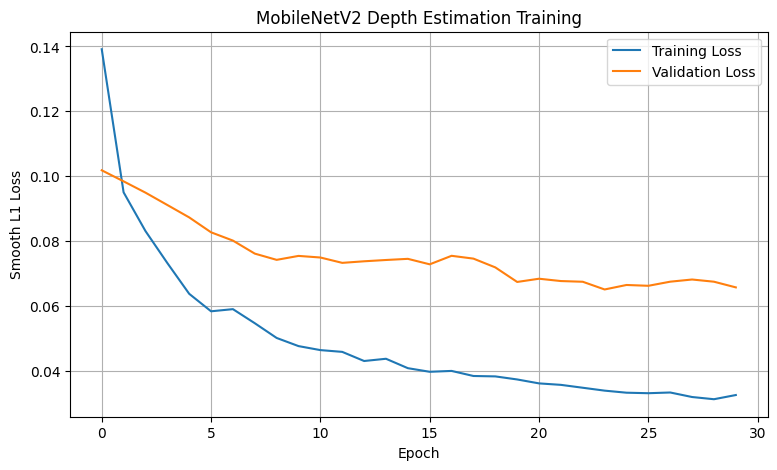


       MOBILENETV2 DEPTH RESULTS
MSE         : 1582.962036
RMSE        : 39.786455
MAE         : 37.010876
Abs Rel     : 1.680690
Delta 1     : 0.013533
Delta 2     : 0.054339
Delta 3     : 0.137015

Predicted Depth:
Min: 32.783905029296875
Max: 140.09707641601562
Mean: 61.872955322265625
Median: 65.68669891357422

Ground Truth Depth:
Min: 10.09450626373291
Max: 88.39826202392578
Mean: 24.971811294555664
Median: 23.640464782714844

Metrics saved: /content/mobilenetv2_depth_metrics.csv
Best model saved: /content/mobilenetv2_depth_best.pth


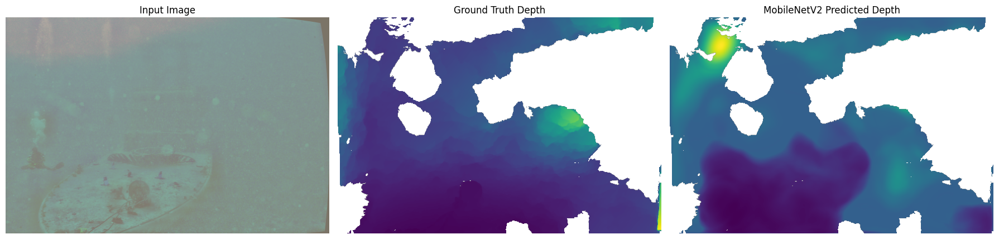


========== FINAL STATUS ==========
Architecture : MobileNetV2
Depth scale : Original scale restored
Evaluation  : Test set
MSE        : 1582.962
RMSE       : 39.7865
MAE        : 37.0109
Abs Rel    : 1.6807
Delta 1    : 0.0135
Delta 2    : 0.0543
Delta 3    : 0.137

Everything completed successfully!


In [66]:

# ============================================================
# ROBUST UNDERWATER MONOCULAR DEPTH ESTIMATION
# MobileNetV2 + Depth Decoder | Complete Training Pipeline
# ============================================================

import os
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import mobilenet_v2, MobileNet_V2_Weights

# -------------------- CONFIGURATION --------------------

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DEPTH_SCALE = 100.0
EPOCHS = 30
ENCODER_LR = 1e-5
DECODER_LR = 1e-4
PATIENCE = 7

MODEL_PATH = "/content/mobilenetv2_depth_best.pth"
CSV_PATH = "/content/mobilenetv2_depth_metrics.csv"

print("Device:", DEVICE)

# -------------------- CHECK DATA LOADERS --------------------

assert "train_loader" in globals(), "train_loader is missing"
assert "val_loader" in globals(), "val_loader is missing"

evaluation_loader = (
    test_loader if "test_loader" in globals()
    else val_loader
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Evaluation:", "test_loader" if "test_loader" in globals() else "val_loader")

# -------------------- MODEL --------------------

class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class MobileNetV2Depth(nn.Module):

    def __init__(self):
        super().__init__()

        weights = MobileNet_V2_Weights.DEFAULT
        backbone = mobilenet_v2(weights=weights)

        self.encoder = backbone.features

        self.decoder = nn.Sequential(
            ConvBlock(1280, 256),
            ConvBlock(256, 128),
            ConvBlock(128, 64),
            ConvBlock(64, 32),
            ConvBlock(32, 16),
            ConvBlock(16, 8),
            nn.Conv2d(8, 1, kernel_size=3, padding=1)
        )

        # ImageNet normalization for pretrained encoder
        self.register_buffer(
            "mean",
            torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
        )

        self.register_buffer(
            "std",
            torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
        )

    def forward(self, x):

        original_size = x.shape[-2:]

        # Assumes dataset images are RGB and in range [0, 1]
        x = (x - self.mean) / self.std

        x = self.encoder(x)

        # Progressive decoder upsampling
        for layer in self.decoder:
            if isinstance(layer, ConvBlock):
                x = F.interpolate(
                    x,
                    scale_factor=2,
                    mode="bilinear",
                    align_corners=False
                )
                x = layer(x)
            else:
                x = layer(x)

        # Ensure output exactly matches input resolution
        x = F.interpolate(
            x,
            size=original_size,
            mode="bilinear",
            align_corners=False
        )

        # Positive depth in normalized scale
        x = F.softplus(x)

        return x


model = MobileNetV2Depth().to(DEVICE)

print("\nMobileNetV2 Depth Model created successfully!")
print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))

# -------------------- LOSS FUNCTION --------------------

def masked_smooth_l1(pred, target, mask):

    mask = mask.bool() & torch.isfinite(target) & (target > 0)

    if mask.sum() == 0:
        return None

    return F.smooth_l1_loss(pred[mask], target[mask])


# -------------------- OPTIMIZER --------------------

optimizer = torch.optim.AdamW(
    [
        {"params": model.encoder.parameters(), "lr": ENCODER_LR},
        {"params": model.decoder.parameters(), "lr": DECODER_LR}
    ],
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

# -------------------- TRAINING / VALIDATION --------------------

def run_epoch(loader, training=True):

    model.train() if training else model.eval()

    total_loss = 0
    total_batches = 0

    context = torch.enable_grad() if training else torch.no_grad()

    with context:

        for images, depths, masks in loader:

            images = images.to(DEVICE, dtype=torch.float32)
            depths = depths.to(DEVICE, dtype=torch.float32)
            masks = masks.to(DEVICE)

            # Scale GT depth for stable training
            scaled_depths = depths / DEPTH_SCALE

            valid_mask = (
                (masks > 0) &
                torch.isfinite(depths) &
                (depths > 0)
            )

            optimizer.zero_grad(set_to_none=True)

            predictions = model(images)

            # Exclude invalid pixels
            loss = masked_smooth_l1(
                predictions,
                scaled_depths,
                valid_mask
            )

            if loss is None:
                continue

            if training:
                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(), max_norm=1.0
                )

                optimizer.step()

            total_loss += loss.item()
            total_batches += 1

    return total_loss / max(total_batches, 1)


# -------------------- TRAIN MODEL --------------------

best_val_loss = float("inf")
best_weights = copy.deepcopy(model.state_dict())
history = {"train_loss": [], "val_loss": []}
patience_counter = 0

print("\n========== TRAINING STARTED ==========\n")

for epoch in range(EPOCHS):

    train_loss = run_epoch(train_loader, training=True)
    val_loss = run_epoch(val_loader, training=False)

    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    current_lr = optimizer.param_groups[1]["lr"]

    print(
        f"Epoch [{epoch+1:02d}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.6f} | "
        f"Val Loss: {val_loss:.6f} | "
        f"Decoder LR: {current_lr:.7f}"
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_weights = copy.deepcopy(model.state_dict())
        patience_counter = 0

        torch.save(best_weights, MODEL_PATH)

        print("  --> Best model saved")

    else:
        patience_counter += 1

    if patience_counter >= PATIENCE:
        print("\nEarly stopping triggered.")
        break

# Load best model
model.load_state_dict(best_weights)
model.eval()

print("\nTraining completed.")
print("Best validation loss:", best_val_loss)

# -------------------- LOSS GRAPH --------------------

plt.figure(figsize=(9, 5))

plt.plot(history["train_loss"], label="Training Loss")
plt.plot(history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Smooth L1 Loss")
plt.title("MobileNetV2 Depth Estimation Training")
plt.legend()
plt.grid(True)
plt.show()

# -------------------- METRIC CALCULATION --------------------

all_predictions = []
all_ground_truth = []

with torch.no_grad():

    for images, depths, masks in evaluation_loader:

        images = images.to(DEVICE, dtype=torch.float32)
        depths = depths.to(DEVICE, dtype=torch.float32)
        masks = masks.to(DEVICE)

        predictions = model(images)

        # Convert back to original depth scale
        predictions = predictions * DEPTH_SCALE

        valid = (
            (masks > 0) &
            torch.isfinite(depths) &
            (depths > 0) &
            torch.isfinite(predictions) &
            (predictions > 0)
        )

        all_predictions.append(predictions[valid].cpu())
        all_ground_truth.append(depths[valid].cpu())

pred = torch.cat(all_predictions)
gt = torch.cat(all_ground_truth)

# -------------------- METRICS --------------------

mse = torch.mean((pred - gt) ** 2).item()
rmse = np.sqrt(mse)
mae = torch.mean(torch.abs(pred - gt)).item()

abs_rel = torch.mean(
    torch.abs(pred - gt) / gt.clamp(min=1e-6)
).item()

ratio = torch.maximum(
    pred / gt.clamp(min=1e-6),
    gt / pred.clamp(min=1e-6)
)

delta1 = (ratio < 1.25).float().mean().item()
delta2 = (ratio < 1.25**2).float().mean().item()
delta3 = (ratio < 1.25**3).float().mean().item()

metrics = {
    "MSE": mse,
    "RMSE": rmse,
    "MAE": mae,
    "Abs Rel": abs_rel,
    "Delta 1": delta1,
    "Delta 2": delta2,
    "Delta 3": delta3
}

# -------------------- PRINT RESULTS --------------------

print("\n" + "=" * 45)
print("       MOBILENETV2 DEPTH RESULTS")
print("=" * 45)

for name, value in metrics.items():
    print(f"{name:12s}: {value:.6f}")

print("\nPredicted Depth:")
print("Min:", pred.min().item())
print("Max:", pred.max().item())
print("Mean:", pred.mean().item())
print("Median:", pred.median().item())

print("\nGround Truth Depth:")
print("Min:", gt.min().item())
print("Max:", gt.max().item())
print("Mean:", gt.mean().item())
print("Median:", gt.median().item())

# -------------------- SAVE METRICS --------------------

df = pd.DataFrame([metrics])
df.to_csv(CSV_PATH, index=False)

print("\nMetrics saved:", CSV_PATH)
print("Best model saved:", MODEL_PATH)

# -------------------- VISUALIZE PREDICTIONS --------------------

model.eval()

with torch.no_grad():

    images, depths, masks = next(iter(evaluation_loader))

    images = images.to(DEVICE, dtype=torch.float32)
    predictions = model(images) * DEPTH_SCALE

    images = images.cpu()
    depths = depths.cpu()
    masks = masks.cpu()
    predictions = predictions.cpu()

    n = min(3, images.shape[0])

    for i in range(n):

        image = images[i].permute(1, 2, 0).numpy()

        # Convert normalized image back to display range
        mean = np.array([0.485, 0.456, 0.406])
        std = np.array([0.229, 0.224, 0.225])

        image = image * std + mean
        image = np.clip(image, 0, 1)

        gt_map = depths[i, 0].numpy()
        pred_map = predictions[i, 0].numpy()
        mask_map = masks[i, 0].numpy() > 0

        gt_display = np.where(mask_map, gt_map, np.nan)
        pred_display = np.where(mask_map, pred_map, np.nan)

        fig, axes = plt.subplots(1, 3, figsize=(18, 5))

        axes[0].imshow(image)
        axes[0].set_title("Input Image")

        axes[1].imshow(gt_display, cmap="viridis")
        axes[1].set_title("Ground Truth Depth")

        axes[2].imshow(pred_display, cmap="viridis")
        axes[2].set_title("MobileNetV2 Predicted Depth")

        for ax in axes:
            ax.axis("off")

        plt.tight_layout()
        plt.show()

# -------------------- FINAL --------------------

print("\n========== FINAL STATUS ==========")
print("Architecture : MobileNetV2")
print("Depth scale : Original scale restored")
print("Evaluation  :", "Test set" if "test_loader" in globals() else "Validation set")
print("MSE        :", round(metrics["MSE"], 4))
print("RMSE       :", round(metrics["RMSE"], 4))
print("MAE        :", round(metrics["MAE"], 4))
print("Abs Rel    :", round(metrics["Abs Rel"], 4))
print("Delta 1    :", round(metrics["Delta 1"], 4))
print("Delta 2    :", round(metrics["Delta 2"], 4))
print("Delta 3    :", round(metrics["Delta 3"], 4))
print("\nEverything completed successfully!")


Device: cuda
Model initialized successfully.
Trainable parameters: 6352465

========== TRAINING START ==========

Epoch 01/35 | Train Loss: 0.67341 | Val Loss: 0.45630
  Best model saved!
Epoch 02/35 | Train Loss: 0.58571 | Val Loss: 0.46512
Epoch 03/35 | Train Loss: 0.58986 | Val Loss: 0.47348
Epoch 04/35 | Train Loss: 0.54206 | Val Loss: 0.47966
Epoch 05/35 | Train Loss: 0.50385 | Val Loss: 0.48276
Epoch 06/35 | Train Loss: 0.47364 | Val Loss: 0.48380
Epoch 07/35 | Train Loss: 0.48365 | Val Loss: 0.48027
Epoch 08/35 | Train Loss: 0.46279 | Val Loss: 0.47111
Epoch 09/35 | Train Loss: 0.44711 | Val Loss: 0.45996
Early stopping.

Training finished.
Best validation loss: 0.45630019903182983


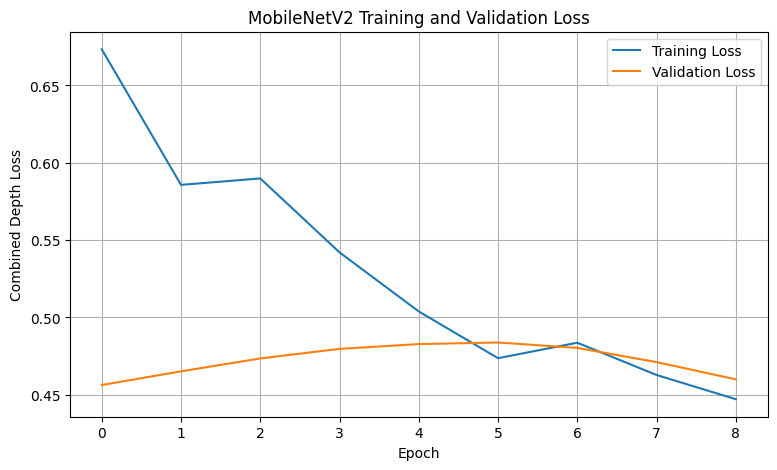


       MOBILENETV2 FINAL RESULTS
MSE         : 1937.191284
RMSE        : 44.013535
MAE         : 42.927700
Abs Rel     : 2.123371
Delta 1     : 0.016600
Delta 2     : 0.061946
Delta 3     : 0.112363

PREDICTION STATISTICS
Predicted Min: 66.61548614501953
Predicted Max: 67.9616928100586
Predicted Mean: 67.84925079345703
Predicted Median: 67.85601043701172

GROUND TRUTH STATISTICS
GT Min: 10.09450626373291
GT Max: 88.39826202392578
GT Mean: 24.971811294555664
GT Median: 23.640464782714844

Metrics saved: /content/mobilenetv2_corrected_metrics.csv
Model saved: /content/mobilenetv2_corrected_best.pth


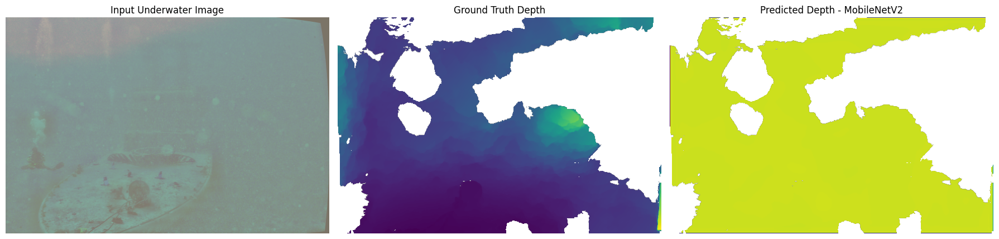


============== FINAL STATUS ==============
Architecture : MobileNetV2
Decoder     : 5-stage progressive decoder
Depth Scale: Original scale
Evaluation : Test set
MSE         : 1937.191284
RMSE        : 44.013535
MAE         : 42.927700
Abs Rel     : 2.123371
Delta 1     : 0.016600
Delta 2     : 0.061946
Delta 3     : 0.112363

Pipeline completed successfully!


In [67]:

# ============================================================
# UNDERWATER MONOCULAR DEPTH ESTIMATION
# MobileNetV2 + Correct 5-Stage Decoder
# SQUID Dataset | Complete Pipeline
# ============================================================

import copy
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import mobilenet_v2, MobileNet_V2_Weights

# ======================== CONFIG ========================

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DEPTH_SCALE = 100.0
EPOCHS = 35
PATIENCE = 8

ENCODER_LR = 1e-5
DECODER_LR = 1e-4

MODEL_PATH = "/content/mobilenetv2_corrected_best.pth"
METRICS_PATH = "/content/mobilenetv2_corrected_metrics.csv"

print("Device:", DEVICE)

assert "train_loader" in globals(), "train_loader missing"
assert "val_loader" in globals(), "val_loader missing"

eval_loader = test_loader if "test_loader" in globals() else val_loader

# ======================== MODEL ========================

class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.layers(x)


class MobileNetV2Depth(nn.Module):

    def __init__(self):
        super().__init__()

        backbone = mobilenet_v2(
            weights=MobileNet_V2_Weights.DEFAULT
        )

        self.encoder = backbone.features

        # Exactly 5 decoder stages:
        # 12x18 -> 24x36 -> 48x72 -> 96x144
        #        -> 192x288 -> 384x576

        self.decoder1 = ConvBlock(1280, 256)
        self.decoder2 = ConvBlock(256, 128)
        self.decoder3 = ConvBlock(128, 64)
        self.decoder4 = ConvBlock(64, 32)
        self.decoder5 = ConvBlock(32, 16)

        self.depth_head = nn.Conv2d(16, 1, kernel_size=3, padding=1)

        # ImageNet normalization
        self.register_buffer(
            "mean",
            torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
        )

        self.register_buffer(
            "std",
            torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
        )

    def forward(self, x):

        original_size = x.shape[-2:]

        # Pretrained encoder preprocessing
        x = (x - self.mean) / self.std

        x = self.encoder(x)

        decoder_blocks = [
            self.decoder1,
            self.decoder2,
            self.decoder3,
            self.decoder4,
            self.decoder5
        ]

        # Progressive upsampling with exactly 5 stages
        for i, block in enumerate(decoder_blocks):

            if i < 4:
                target_size = (
                    x.shape[-2] * 2,
                    x.shape[-1] * 2
                )
            else:
                target_size = original_size

            x = F.interpolate(
                x,
                size=target_size,
                mode="bilinear",
                align_corners=False
            )

            x = block(x)

        # Positive normalized depth
        x = F.softplus(self.depth_head(x))

        return x


model = MobileNetV2Depth().to(DEVICE)

print("Model initialized successfully.")
print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))

# ======================== LOSS ========================

def depth_loss(pred, target, mask):

    mask = (
        mask.bool()
        & torch.isfinite(target)
        & (target > 0)
        & torch.isfinite(pred)
    )

    if mask.sum() == 0:
        return None

    p = pred[mask].clamp(min=1e-5)
    t = target[mask].clamp(min=1e-5)

    # Stable scale-sensitive loss
    l1_loss = F.smooth_l1_loss(p, t)

    # Relative depth loss
    log_loss = torch.mean(torch.abs(torch.log(p) - torch.log(t)))

    # Combined objective
    loss = 0.7 * l1_loss + 0.3 * log_loss

    return loss


# ======================== OPTIMIZER ========================

optimizer = torch.optim.AdamW(
    [
        {"params": model.encoder.parameters(), "lr": ENCODER_LR},
        {
            "params": list(model.decoder1.parameters())
                    + list(model.decoder2.parameters())
                    + list(model.decoder3.parameters())
                    + list(model.decoder4.parameters())
                    + list(model.decoder5.parameters())
                    + list(model.depth_head.parameters()),
            "lr": DECODER_LR
        }
    ],
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

# ======================== TRAIN / VALIDATE ========================

def run_epoch(loader, training):

    if training:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    batches = 0

    context = torch.enable_grad() if training else torch.no_grad()

    with context:

        for images, depths, masks in loader:

            images = images.to(DEVICE, dtype=torch.float32)
            depths = depths.to(DEVICE, dtype=torch.float32)
            masks = masks.to(DEVICE)

            # Scale GT depth
            target = depths / DEPTH_SCALE

            valid_mask = (
                (masks > 0)
                & torch.isfinite(depths)
                & (depths > 0)
            )

            if training:
                optimizer.zero_grad(set_to_none=True)

            prediction = model(images)

            loss = depth_loss(
                prediction,
                target,
                valid_mask
            )

            if loss is None:
                continue

            if training:
                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    1.0
                )

                optimizer.step()

            total_loss += loss.item()
            batches += 1

    return total_loss / max(batches, 1)


# ======================== TRAINING ========================

best_val_loss = float("inf")
best_weights = copy.deepcopy(model.state_dict())

history = {
    "train_loss": [],
    "val_loss": []
}

counter = 0

print("\n========== TRAINING START ==========\n")

for epoch in range(EPOCHS):

    train_loss = run_epoch(train_loader, training=True)
    val_loss = run_epoch(val_loader, training=False)

    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.5f} | "
        f"Val Loss: {val_loss:.5f}"
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_weights = copy.deepcopy(model.state_dict())
        counter = 0

        torch.save(best_weights, MODEL_PATH)

        print("  Best model saved!")

    else:
        counter += 1

    if counter >= PATIENCE:
        print("Early stopping.")
        break

model.load_state_dict(best_weights)
model.eval()

print("\nTraining finished.")
print("Best validation loss:", best_val_loss)

# ======================== LOSS PLOT ========================

plt.figure(figsize=(9, 5))

plt.plot(history["train_loss"], label="Training Loss")
plt.plot(history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Combined Depth Loss")
plt.title("MobileNetV2 Training and Validation Loss")
plt.legend()
plt.grid()
plt.show()

# ======================== EVALUATION ========================

predictions_all = []
ground_truth_all = []

with torch.no_grad():

    for images, depths, masks in eval_loader:

        images = images.to(DEVICE, dtype=torch.float32)
        depths = depths.to(DEVICE, dtype=torch.float32)
        masks = masks.to(DEVICE)

        pred = model(images)

        # Restore original depth scale
        pred = pred * DEPTH_SCALE

        valid = (
            (masks > 0)
            & torch.isfinite(depths)
            & (depths > 0)
            & torch.isfinite(pred)
            & (pred > 0)
        )

        predictions_all.append(pred[valid].cpu())
        ground_truth_all.append(depths[valid].cpu())

pred = torch.cat(predictions_all)
gt = torch.cat(ground_truth_all)

# ======================== METRICS ========================

mse = torch.mean((pred - gt) ** 2).item()
rmse = np.sqrt(mse)

mae = torch.mean(torch.abs(pred - gt)).item()

abs_rel = torch.mean(
    torch.abs(pred - gt) / gt.clamp(min=1e-6)
).item()

ratio = torch.maximum(
    pred / gt.clamp(min=1e-6),
    gt / pred.clamp(min=1e-6)
)

delta1 = (ratio < 1.25).float().mean().item()
delta2 = (ratio < 1.25**2).float().mean().item()
delta3 = (ratio < 1.25**3).float().mean().item()

metrics = {
    "MSE": mse,
    "RMSE": rmse,
    "MAE": mae,
    "Abs Rel": abs_rel,
    "Delta 1": delta1,
    "Delta 2": delta2,
    "Delta 3": delta3
}

# ======================== PRINT RESULTS ========================

print("\n========================================")
print("       MOBILENETV2 FINAL RESULTS")
print("========================================")

for key, value in metrics.items():
    print(f"{key:12}: {value:.6f}")

print("\nPREDICTION STATISTICS")
print("Predicted Min:", pred.min().item())
print("Predicted Max:", pred.max().item())
print("Predicted Mean:", pred.mean().item())
print("Predicted Median:", pred.median().item())

print("\nGROUND TRUTH STATISTICS")
print("GT Min:", gt.min().item())
print("GT Max:", gt.max().item())
print("GT Mean:", gt.mean().item())
print("GT Median:", gt.median().item())

# ======================== SAVE CSV ========================

pd.DataFrame([metrics]).to_csv(METRICS_PATH, index=False)

print("\nMetrics saved:", METRICS_PATH)
print("Model saved:", MODEL_PATH)

# ======================== VISUALIZATION ========================

with torch.no_grad():

    images, depths, masks = next(iter(eval_loader))

    images = images.to(DEVICE, dtype=torch.float32)

    pred_maps = (model(images) * DEPTH_SCALE).cpu()

    images = images.cpu()
    depths = depths.cpu()
    masks = masks.cpu()

    count = min(3, images.shape[0])

    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    for i in range(count):

        image = images[i].permute(1, 2, 0).numpy()

        # Display RGB image
        image = image * std + mean
        image = np.clip(image, 0, 1)

        gt_map = depths[i, 0].numpy()
        pred_map = pred_maps[i, 0].numpy()

        mask = masks[i, 0].numpy() > 0

        gt_map = np.where(mask, gt_map, np.nan)
        pred_map = np.where(mask, pred_map, np.nan)

        fig, axes = plt.subplots(1, 3, figsize=(18, 5))

        axes[0].imshow(image)
        axes[0].set_title("Input Underwater Image")

        axes[1].imshow(gt_map, cmap="viridis")
        axes[1].set_title("Ground Truth Depth")

        axes[2].imshow(pred_map, cmap="viridis")
        axes[2].set_title("Predicted Depth - MobileNetV2")

        for ax in axes:
            ax.axis("off")

        plt.tight_layout()
        plt.show()

# ======================== FINAL REPORT ========================

print("\n============== FINAL STATUS ==============")
print("Architecture : MobileNetV2")
print("Decoder     : 5-stage progressive decoder")
print("Depth Scale: Original scale")
print("Evaluation :", "Test set" if "test_loader" in globals() else "Validation set")

for key, value in metrics.items():
    print(f"{key:12}: {value:.6f}")

print("\nPipeline completed successfully!")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Device: cuda

Loading pretrained YOLOv8n...
YOLO backbone loaded.
Feature extraction layer: 9

YOLO Depth Model ready!

========== YOLO TRAINING START ==========

Epoch [1/30] | Train Loss: 0.687257 | Val Loss: 0.519052
  --> Best model saved
Epoch [2/30] | Train Loss: 0.620740 | Val Loss: 0.528564
Epoch [3/30] | Train Loss: 0.594096 | Val Loss: 0.535741
Epoch [4/30] | Train Loss: 0.558937 | Val Loss: 0.541620
Epoch [5/30] | Train Loss: 0.537339 | Val Loss: 0.543636
Epoch [6/30] | Train Loss: 0.529942 | Val Loss: 0.547505
Epoch [7/30] | Train Loss: 0.508045 | Val Loss: 0.549255
Epoch [8/30] | Train Loss: 0.516075 | Val Loss: 0.550415

Early stopping.

YOLO training completed.


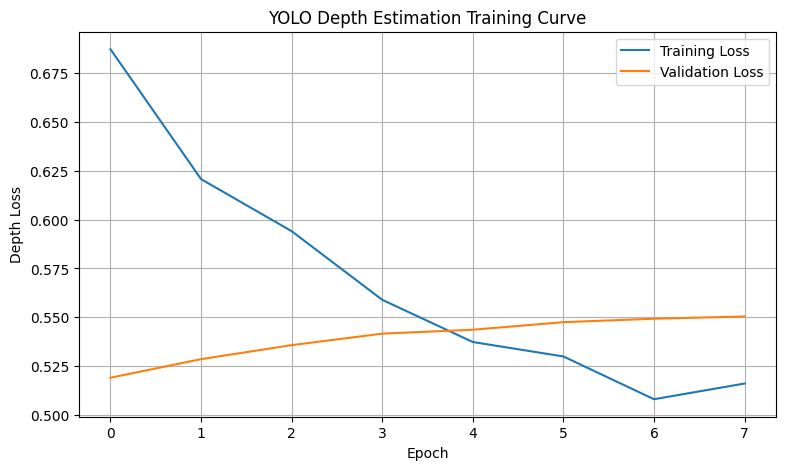


         YOLO DEPTH RESULTS
MSE         : 2696.406982
RMSE        : 51.926939
MAE         : 50.986904
Abs Rel     : 2.495272
Delta 1     : 0.010559
Delta 2     : 0.031734
Delta 3     : 0.086232

PREDICTED DEPTH
Min: 74.8817138671875
Max: 76.32643127441406
Mean: 75.94049072265625
Median: 75.94390869140625

GROUND TRUTH DEPTH
Min: 10.09450626373291
Max: 88.39826202392578
Mean: 24.971811294555664
Median: 23.640464782714844

Metrics saved to: /content/yolo_depth_metrics.csv
Model saved to: /content/yolo_depth_best.pth


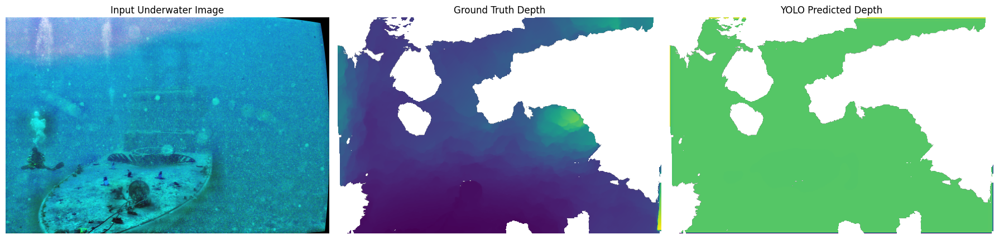


========== FINAL STATUS ==========
Architecture : YOLOv8n + Depth Decoder
Task       : Dense Monocular Depth Estimation
Evaluation : Test Set
MSE         : 2696.406982
RMSE        : 51.926939
MAE         : 50.986904
Abs Rel     : 2.495272
Delta 1     : 0.010559
Delta 2     : 0.031734
Delta 3     : 0.086232

YOLO depth pipeline finished successfully!


In [68]:

# ============================================================
# ROBUST UNDERWATER MONOCULAR DEPTH ESTIMATION
# YOLOv8n BACKBONE + CUSTOM DENSE DEPTH DECODER
# SQUID DATASET | COMPLETE PIPELINE
# ============================================================

# Install Ultralytics
!pip -q install ultralytics

import os
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from ultralytics import YOLO

# ============================================================
# CONFIGURATION
# ============================================================

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DEPTH_SCALE = 100.0
EPOCHS = 30
PATIENCE = 7
LEARNING_RATE = 1e-4

MODEL_PATH = "/content/yolo_depth_best.pth"
CSV_PATH = "/content/yolo_depth_metrics.csv"

print("Device:", DEVICE)

assert "train_loader" in globals(), "train_loader not found"
assert "val_loader" in globals(), "val_loader not found"

evaluation_loader = (
    test_loader if "test_loader" in globals()
    else val_loader
)

# ============================================================
# YOLOv8 BACKBONE
# ============================================================

print("\nLoading pretrained YOLOv8n...")

yolo = YOLO("yolov8n.pt")

yolo_model = yolo.model.to(DEVICE)
yolo_model.eval()

# Freeze pretrained YOLO parameters
for param in yolo_model.parameters():
    param.requires_grad = False

# Layer 9 is the SPPF feature block in standard YOLOv8n.
# It provides a deep feature map at approximately 1/32 resolution.
FEATURE_LAYER_INDEX = 9

feature_storage = {}

def feature_hook(module, inputs, output):
    feature_storage["feature"] = output

hook_handle = yolo_model.model[FEATURE_LAYER_INDEX].register_forward_hook(
    feature_hook
)

print("YOLO backbone loaded.")
print("Feature extraction layer:", FEATURE_LAYER_INDEX)

# ============================================================
# DEPTH DECODER
# ============================================================

class ConvBlock(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels, out_channels,
                kernel_size=3, padding=1, bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels, out_channels,
                kernel_size=3, padding=1, bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class YOLODepthModel(nn.Module):

    def __init__(self, yolo_model):
        super().__init__()

        self.yolo_model = yolo_model

        # YOLOv8n SPPF layer output channels = 256
        self.decoder1 = ConvBlock(256, 128)
        self.decoder2 = ConvBlock(128, 64)
        self.decoder3 = ConvBlock(64, 32)
        self.decoder4 = ConvBlock(32, 16)
        self.decoder5 = ConvBlock(16, 8)

        self.depth_head = nn.Conv2d(
            8, 1, kernel_size=3, padding=1
        )

    def forward(self, images):

        original_size = images.shape[-2:]

        # Extract YOLO features using the registered hook
        with torch.no_grad():
            feature_storage.clear()
            _ = self.yolo_model(images)

            features = feature_storage["feature"]

        # Decoder progressive upsampling
        x = features

        decoder_layers = [
            self.decoder1,
            self.decoder2,
            self.decoder3,
            self.decoder4,
            self.decoder5
        ]

        for i, layer in enumerate(decoder_layers):

            if i < 4:
                size = (
                    x.shape[-2] * 2,
                    x.shape[-1] * 2
                )
            else:
                size = original_size

            x = F.interpolate(
                x,
                size=size,
                mode="bilinear",
                align_corners=False
            )

            x = layer(x)

        # Dense positive depth prediction
        x = F.softplus(self.depth_head(x))

        return x


model = YOLODepthModel(yolo_model).to(DEVICE)

print("\nYOLO Depth Model ready!")

# ============================================================
# LOSS FUNCTION
# ============================================================

def masked_depth_loss(pred, target, mask):

    valid = (
        mask.bool()
        & torch.isfinite(target)
        & (target > 0)
        & torch.isfinite(pred)
    )

    if valid.sum() == 0:
        return None

    p = pred[valid].clamp(min=1e-6)
    t = target[valid].clamp(min=1e-6)

    # Absolute scale loss
    l1 = F.smooth_l1_loss(p, t)

    # Relative depth loss
    log_loss = torch.mean(
        torch.abs(torch.log(p) - torch.log(t))
    )

    return 0.7 * l1 + 0.3 * log_loss

# ============================================================
# OPTIMIZER
# ============================================================

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

# ============================================================
# TRAINING FUNCTION
# ============================================================

def run_epoch(loader, training=True):

    model.train() if training else model.eval()

    # Keep YOLO backbone in evaluation mode
    model.yolo_model.eval()

    total_loss = 0.0
    batches = 0

    for images, depths, masks in loader:

        images = images.to(DEVICE, dtype=torch.float32)
        depths = depths.to(DEVICE, dtype=torch.float32)
        masks = masks.to(DEVICE)

        targets = depths / DEPTH_SCALE

        valid_mask = (
            (masks > 0)
            & torch.isfinite(depths)
            & (depths > 0)
        )

        if training:
            optimizer.zero_grad(set_to_none=True)

        predictions = model(images)

        loss = masked_depth_loss(
            predictions,
            targets,
            valid_mask
        )

        if loss is None:
            continue

        if training:

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(), 1.0
            )

            optimizer.step()

        total_loss += loss.item()
        batches += 1

    return total_loss / max(batches, 1)

# ============================================================
# TRAINING
# ============================================================

best_val_loss = float("inf")
best_weights = copy.deepcopy(model.state_dict())

history = {
    "train_loss": [],
    "val_loss": []
}

patience_counter = 0

print("\n========== YOLO TRAINING START ==========\n")

for epoch in range(EPOCHS):

    train_loss = run_epoch(
        train_loader, training=True
    )

    val_loss = run_epoch(
        val_loader, training=False
    )

    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.6f} | "
        f"Val Loss: {val_loss:.6f}"
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_weights = copy.deepcopy(model.state_dict())

        torch.save(best_weights, MODEL_PATH)

        patience_counter = 0
        print("  --> Best model saved")

    else:
        patience_counter += 1

    if patience_counter >= PATIENCE:
        print("\nEarly stopping.")
        break

# Load best model
model.load_state_dict(best_weights)
model.eval()

print("\nYOLO training completed.")

# ============================================================
# TRAINING GRAPH
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(history["train_loss"], label="Training Loss")
plt.plot(history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Depth Loss")
plt.title("YOLO Depth Estimation Training Curve")
plt.legend()
plt.grid()
plt.show()

# ============================================================
# EVALUATION
# ============================================================

all_pred = []
all_gt = []

model.eval()

with torch.no_grad():

    for images, depths, masks in evaluation_loader:

        images = images.to(DEVICE, dtype=torch.float32)
        depths = depths.to(DEVICE, dtype=torch.float32)
        masks = masks.to(DEVICE)

        predictions = model(images) * DEPTH_SCALE

        valid = (
            (masks > 0)
            & torch.isfinite(depths)
            & (depths > 0)
            & torch.isfinite(predictions)
            & (predictions > 0)
        )

        all_pred.append(predictions[valid].cpu())
        all_gt.append(depths[valid].cpu())

pred = torch.cat(all_pred)
gt = torch.cat(all_gt)

# ============================================================
# METRICS
# ============================================================

mse = torch.mean((pred - gt) ** 2).item()
rmse = np.sqrt(mse)

mae = torch.mean(
    torch.abs(pred - gt)
).item()

abs_rel = torch.mean(
    torch.abs(pred - gt) / gt.clamp(min=1e-6)
).item()

ratio = torch.maximum(
    pred / gt.clamp(min=1e-6),
    gt / pred.clamp(min=1e-6)
)

delta1 = (ratio < 1.25).float().mean().item()
delta2 = (ratio < 1.25**2).float().mean().item()
delta3 = (ratio < 1.25**3).float().mean().item()

metrics = {
    "MSE": mse,
    "RMSE": rmse,
    "MAE": mae,
    "Abs Rel": abs_rel,
    "Delta 1": delta1,
    "Delta 2": delta2,
    "Delta 3": delta3
}

# ============================================================
# RESULTS
# ============================================================

print("\n==========================================")
print("         YOLO DEPTH RESULTS")
print("==========================================")

for name, value in metrics.items():
    print(f"{name:12}: {value:.6f}")

print("\nPREDICTED DEPTH")
print("Min:", pred.min().item())
print("Max:", pred.max().item())
print("Mean:", pred.mean().item())
print("Median:", pred.median().item())

print("\nGROUND TRUTH DEPTH")
print("Min:", gt.min().item())
print("Max:", gt.max().item())
print("Mean:", gt.mean().item())
print("Median:", gt.median().item())

# ============================================================
# SAVE METRICS
# ============================================================

pd.DataFrame([metrics]).to_csv(
    CSV_PATH,
    index=False
)

print("\nMetrics saved to:", CSV_PATH)
print("Model saved to:", MODEL_PATH)

# ============================================================
# VISUALIZATION
# ============================================================

with torch.no_grad():

    images, depths, masks = next(
        iter(evaluation_loader)
    )

    images = images.to(DEVICE, dtype=torch.float32)

    pred_maps = (
        model(images) * DEPTH_SCALE
    ).cpu()

    images = images.cpu()
    depths = depths.cpu()
    masks = masks.cpu()

    n = min(3, images.shape[0])

    for i in range(n):

        image = images[i].permute(1, 2, 0).numpy()
        image = np.clip(image, 0, 1)

        gt_map = depths[i, 0].numpy()
        pred_map = pred_maps[i, 0].numpy()

        mask = masks[i, 0].numpy() > 0

        gt_map = np.where(mask, gt_map, np.nan)
        pred_map = np.where(mask, pred_map, np.nan)

        fig, axes = plt.subplots(
            1, 3, figsize=(18, 5)
        )

        axes[0].imshow(image)
        axes[0].set_title("Input Underwater Image")

        axes[1].imshow(gt_map, cmap="viridis")
        axes[1].set_title("Ground Truth Depth")

        axes[2].imshow(pred_map, cmap="viridis")
        axes[2].set_title("YOLO Predicted Depth")

        for ax in axes:
            ax.axis("off")

        plt.tight_layout()
        plt.show()

# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n========== FINAL STATUS ==========")
print("Architecture : YOLOv8n + Depth Decoder")
print("Task       : Dense Monocular Depth Estimation")
print("Evaluation :", "Test Set" if "test_loader" in globals() else "Validation Set")

for name, value in metrics.items():
    print(f"{name:12}: {value:.6f}")

print("\nYOLO depth pipeline finished successfully!")

# Remove hook after experiment
hook_handle.remove()
